In [1]:
# Opción para python 3.12 [gráficos de plotly en notebook]
import plotly.offline as pyo
import plotly.graph_objs as go

# Set notebook mode to work in offline
pyo.init_notebook_mode()

Output hidden; open in https://colab.research.google.com to view.

# Introducción y esquema de trabajo

A lo largo de este documento se desarrolla el procedimiento básico para enfrentarse a un análisis de *Regresión Logística con selección de variables* cuando los datos de entrada se encuentran previamente depurados. Se puede esquematizar el proceso como sigue:

1.  Construcción de modelos manuales
2.  Esquema de se lección de variables clásico bajo el esquema Training/Test
    -   Efectos principales
    -   Efectos principales + transformaciones
    -   Efectos principales + transformaciones + interacciones
3.  Esquema de comprobación de resultados por Validación Cruzada Repetida
    -   Considerando los mejores modelos de entre los anteriores tratamos de evitar la influencia de la semilla de inicialización de las particiones.

4.  Elección del modelo final
    -   Evaluación
    -   Interpretación

# Preámbulo y lectura de datos

En primer lugar, cargaremos funciones y leeremos el conjunto de datos. En este documento, damos por depurado el archivo de entrada, ya que esta fase ya fue completada previamente. Recordemos que utilizamos el archivo con winsor de outliers detectados e imputación por aleatorio de los valores perdidos, pero otras posibilidades son perfectamente válidas, habrá que probar otras alternativas, no?


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd
import numpy as np
pd.set_option("display.max_rows", None, "display.max_columns", None)


# Configuración warnings
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

# Si las funciones están en esta misma carpeta podemos hacer
#from NuestrasFunciones import *

# De lo contrario podemos hacer algo así como...
#execfile('C:\\Users\\Guille\\Documents\\Material Minería de Datos 2024_25 Gr3\\NuestrasFunciones.py')

# O bien esto
exec(open('/content/drive/MyDrive/Documentación minería de datos y modelización predictiva - Elena Gavilán y Daniel Martín-20260123/Datos parte 2/NuestrasFunciones.py').read())
# De lo contrario podemos hacer algo así como...
#execfile('/content/drive/MyDrive/Material Minería de Datos 2025_26 Gr2/NuestrasFunciones.py')

# Leer datos depurados datosvinoDep
viviendasDep = pd.read_hdf(r'/content/drive/MyDrive/Documentación minería de datos y modelización predictiva - Elena Gavilán y Daniel Martín-20260123/Datos parte 2/DatosViviendasDep_wins_itImp_moda_v2.h5',key='df')


# Descriptivo de comprobación
viviendasDep.head()


,month,bathrooms,sqft_living,sqft_above,yr_built,lat,long,bedrooms_cont,log_sqft_lot,prop_missings,year,floors,waterfront,view,condition,basement,yr_renovated,bedrooms_cat,price,Luxury
0,7.0,2.5,2070.0,1540.0,1980.0,47.5936,-122.013,3.0,9.301094,5.882353,2014,1.0,0,0,CD,1,0,3,653450,1
1,6.0,1.5,1640.0,1540.0,1916.0,47.6624,-122.325,2.0,9.053580,5.882353,2014,1.5,0,0,A,1,0,2,710000,1
2,10.0,3.5,3720.0,3720.0,2007.0,47.3216,-121.940,4.0,10.139560,5.882353,2014,1.0,0,1,B,0,0,4,780000,1
3,12.0,3.5,2260.0,1880.0,2003.0,47.6422,-122.361,3.0,8.218188,5.882353,2014,2.0,0,0,B,1,0,3,795000,1
4,10.0,2.0,2050.0,1170.0,1960.0,47.7447,-122.328,3.0,8.650238,5.882353,2014,1.0,0,0,A,1,0,3,399950,0


Como ya sabemos, al guardar y leer se nos estropean los tipos y los tenemos que volver a ajustar a nuestro gusto. En este caso, como alguna variable como floors o prop_missings tiene menos de 10 valores distintos y, sin embargo queremos que sean continuas, podemos especificar su tipo numérico a posteriori.


In [4]:
viviendasDep.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4999 entries, 0 to 4998
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   month          4999 non-null   float64 
 1   bathrooms      4999 non-null   float64 
 2   sqft_living    4999 non-null   float64 
 3   sqft_above     4999 non-null   float64 
 4   yr_built       4999 non-null   float64 
 5   lat            4999 non-null   float64 
 6   long           4999 non-null   float64 
 7   bedrooms_cont  4999 non-null   float64 
 8   log_sqft_lot   4999 non-null   float64 
 9   prop_missings  4999 non-null   float64 
 10  year           4999 non-null   category
 11  floors         4999 non-null   category
 12  waterfront     4999 non-null   category
 13  view           4999 non-null   category
 14  condition      4999 non-null   category
 15  basement       4999 non-null   category
 16  yr_renovated   4999 non-null   category
 17  bedrooms_cat   4999 non-null   categor

In [5]:
# Lista de columnas con menos de 10 valores distintos. Potenciales factores!
#to_factor = list(viviendasDep.loc[:,viviendasDep.nunique() < 8]);

# Podemos cambiar el tipo de todas ellas a factor de una vez
#viviendasDep[to_factor] = viviendasDep[to_factor].astype('category')

viviendasDep['floors']=viviendasDep['floors'].astype('float64')
viviendasDep['prop_missings']=viviendasDep['prop_missings'].astype('float64')

viviendasDep.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4999 entries, 0 to 4998
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   month          4999 non-null   float64 
 1   bathrooms      4999 non-null   float64 
 2   sqft_living    4999 non-null   float64 
 3   sqft_above     4999 non-null   float64 
 4   yr_built       4999 non-null   float64 
 5   lat            4999 non-null   float64 
 6   long           4999 non-null   float64 
 7   bedrooms_cont  4999 non-null   float64 
 8   log_sqft_lot   4999 non-null   float64 
 9   prop_missings  4999 non-null   float64 
 10  year           4999 non-null   category
 11  floors         4999 non-null   float64 
 12  waterfront     4999 non-null   category
 13  view           4999 non-null   category
 14  condition      4999 non-null   category
 15  basement       4999 non-null   category
 16  yr_renovated   4999 non-null   category
 17  bedrooms_cat   4999 non-null   categor

In [6]:
# Ordenmaos categorías de los fatcores de interés
viviendasDep["condition"] = viviendasDep["condition"].cat.reorder_categories(['Desc','A','B','CD'])
#viviendasDep["Clasificacion"] = viviendasDep["Clasificacion"].cat.reorder_categories(['Desc','*','**','***','****'])

Tipos correctos. Continuar!

En este caso, debido que nos enfrentamos a un problema de clasificación binaria, sería conveniente mirar desde ya la distribución de nuestra variable objetivo en especial para evaluar el desbalanceo de clases y poder intuir el sentido de las limitaciones del futuro modelo.

- Si hay pocos 0, va a tener problemas de especificidad
- Si hay pocos 1, va a tener problemas de sensibilidad

Así, ponemos sobre aviso al lector del informe, y tal vez nos guardamos ese warning para mirar bien las métricas de evaluación..especialmente no utilizar Accuracy en un escenario muy desbalanceado ya que es un pecado capital!


In [7]:
viviendasDep.Luxury.value_counts(normalize=True)



,proportion
Luxury,
0,0.577315
1,0.422685


Situación bastante favorable para el modelo de clasificación con un 42/58% de evento/no evento. No hay mucho desbalanceo por lo que intuimos que el accuracy no será una métrica catastrófica y que si movemos el pto de corte para maximizar el índice de Youden, será solo ligeramente hacia el 0.4 como mucho..

**Variables de control**

Como siempre, nuestros aleatorios de control por si acaso..


In [8]:
viviendasDep['aleatorio'] = np.random.uniform(0,1,size=viviendasDep.shape[0])
viviendasDep['aleatorio2'] = np.random.uniform(0,1,size=viviendasDep.shape[0])
viviendasDep.head()


,month,bathrooms,sqft_living,sqft_above,yr_built,lat,long,bedrooms_cont,log_sqft_lot,prop_missings,year,floors,waterfront,view,condition,basement,yr_renovated,bedrooms_cat,price,Luxury,aleatorio,aleatorio2
0,7.0,2.5,2070.0,1540.0,1980.0,47.5936,-122.013,3.0,9.301094,5.882353,2014,1.0,0,0,CD,1,0,3,653450,1,0.471773,0.625597
1,6.0,1.5,1640.0,1540.0,1916.0,47.6624,-122.325,2.0,9.053580,5.882353,2014,1.5,0,0,A,1,0,2,710000,1,0.967475,0.883987
2,10.0,3.5,3720.0,3720.0,2007.0,47.3216,-121.940,4.0,10.139560,5.882353,2014,1.0,0,1,B,0,0,4,780000,1,0.078995,0.978015
3,12.0,3.5,2260.0,1880.0,2003.0,47.6422,-122.361,3.0,8.218188,5.882353,2014,2.0,0,0,B,1,0,3,795000,1,0.804842,0.558699
4,10.0,2.0,2050.0,1170.0,1960.0,47.7447,-122.328,3.0,8.650238,5.882353,2014,1.0,0,0,A,1,0,3,399950,0,0.215817,0.758183


# Estudio descriptivo de relaciones con la respuesta

En este apartado intentaremos descubrir a priori las relaciones marginales de las variables con la variable objetivo binaria para hacernos una idea de cuales de ellas serán potencialmente influyentes en los modelos de regresión logística que ajustemos.

Separamos input y variable objetivo por aquello de que vamos a pasar funciones a todos los predictores y transformar etc..


In [9]:
# Eliminar variable objetivo continua
varObjBin = viviendasDep.Luxury
inputDep = viviendasDep.drop(['price','Luxury'],axis=1) #,'bedrooms_cat'
inputDep.info()


<class 'pandas.core.frame.DataFrame'>
Index: 4999 entries, 0 to 4998
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   month          4999 non-null   float64 
 1   bathrooms      4999 non-null   float64 
 2   sqft_living    4999 non-null   float64 
 3   sqft_above     4999 non-null   float64 
 4   yr_built       4999 non-null   float64 
 5   lat            4999 non-null   float64 
 6   long           4999 non-null   float64 
 7   bedrooms_cont  4999 non-null   float64 
 8   log_sqft_lot   4999 non-null   float64 
 9   prop_missings  4999 non-null   float64 
 10  year           4999 non-null   category
 11  floors         4999 non-null   float64 
 12  waterfront     4999 non-null   category
 13  view           4999 non-null   category
 14  condition      4999 non-null   category
 15  basement       4999 non-null   category
 16  yr_renovated   4999 non-null   category
 17  bedrooms_cat   4999 non-null   categor

## V Cramer para ranking inicial

Nuestra famosa V de Cramer genera el primer ranking tentativo de efectos a considerar en el modelo. Recordemos que estos valores nos hablan de la relación (lineal o no) de los predictores de todo tipo con la variable objetivo en términos **marginales**, es decir, sin tener en cuenta que puede haber en un modelo multivariante, efectos "solapados" y los famosos efectos de confusión o interacción. Podría ocurrir que un predictor a priori sea muy importante pero en modelo, ese efecto sea recogido (posiblemente mejor) por otra variable, con lo que su efecto dentro de modelo ya no será relevante. Por el contrario, podría suceder que un predictor que a nivel marginal no tenga gran efecto, sea importante en modelo debido a un fenómeno de interacción con otras variable presentes.


In [21]:
# # EL CÓDIGO DEBERÍA SER ESTE, PERO NO SE POR QUÉ, NO FUNCIONA

# #Librería estadística!
#import scipy.stats as stats


# # Aplicar la función al input completo contra la objetivo
#tablaCramer = pd.DataFrame(inputDep.apply(lambda x: cramers_v(x,varObjBin)),columns=['VCramer'])

# # Obtener el gráfico de importancia de las variables frente a la objetivo continua según vcramer
#import plotly.express as px
#px.bar(tablaCramer,x=tablaCramer.VCramer,title='Relaciones frente a Compra').update_yaxes(categoryorder="total ascending").show()

In [28]:
# 1. Calculamos y reseteamos el índice en el mismo paso para evitar errores de dimensión
tablaCramer = pd.DataFrame(inputDep.apply(lambda x: cramers_v(x, varObjBin)))
tablaCramer = tablaCramer.reset_index()

# 2. Ahora sí tenemos 2 columnas garantizadas. Renombramos:
tablaCramer.columns = ['Variable', 'VCramer']

# 3. Ordenamos por valor para que el gráfico tenga sentido
tablaCramer = tablaCramer.sort_values('VCramer', ascending=True)

# 4. Graficamos
fig = px.bar(tablaCramer,
             x='VCramer',
             y='Variable',
             orientation='h',
             text_auto='.3f',  # Muestra el valor exacto en la barra
             title='Importancia de Variables (V de Cramer)')

fig.show()


En este caso tenemos que las variables tentativas para el modelado son:

- sqft_living
- lat
- sqft_above
- bathrooms
- bedrooms (cualquier variante)
- floors
- view
- basement
....

Los aleatorios aparecen bastante abajo, buena señal.


## Evaluación gráfica por variable o interación

Como siempre, podemos detenernos a evaluar sentido de los efectos de los predictores de forma gráfica. Por ejemplo, ilustramos el tema de coordenadas, discrimina más longitud o latitud? Hay patrón conjunto interesante?


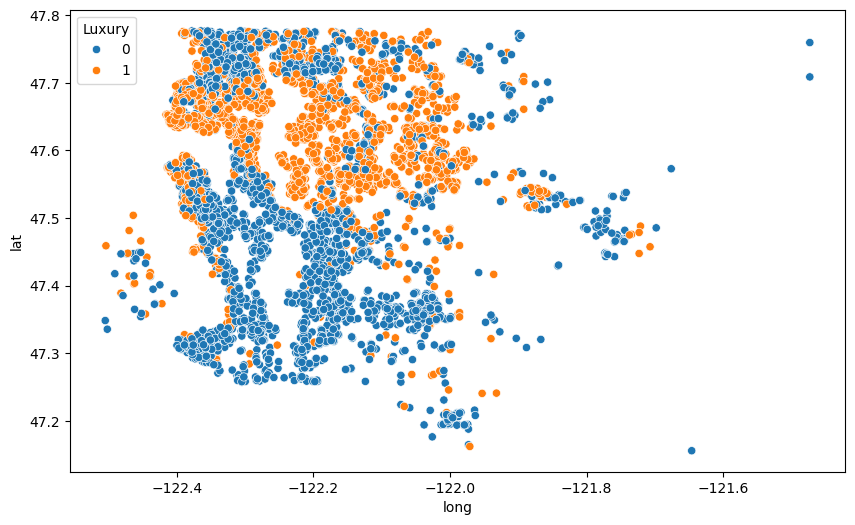

In [18]:
plt.rcParams["figure.figsize"] = (10,6)
plt.clf()
sns.scatterplot(data=viviendasDep, x="long", y="lat", hue="Luxury")
#sns.boxplot(x='long',y='Luxury',data=viviendasDep,palette='viridis')
plt.show()


Parece claro que latitud es la que genera patrón relevante.

Veamos el efecto de la superficie del salón y cruzamos con latitud.


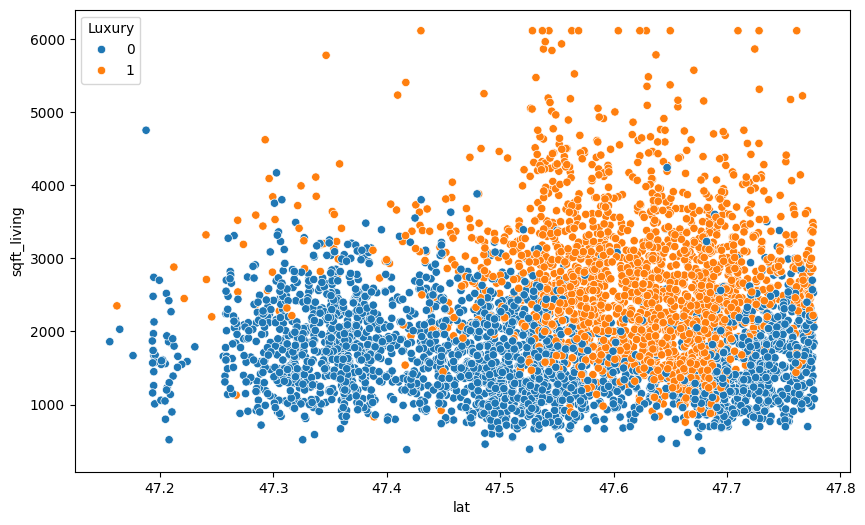

In [19]:
plt.clf()
sns.scatterplot(data=viviendasDep, x="lat", y="sqft_living", hue="Luxury")
#sns.boxplot(x='sqft_living',y='Luxury',data=viviendasDep,palette='viridis')
plt.show()


Parece que ambos valores altos maximizan la probabilidad de vivienda de lujo..Posible interacción. Me planteo aquí la posibilidad de tramificar lat en dos grupos de tal forma que la probabilidad condicionada por el valor de sqft_living sea muy distinto en los dos..tipo corte ente 47.4 y 47.5 podría funcionar..



Creamos algún mosaico para nominales.


<Figure size 1000x600 with 0 Axes>

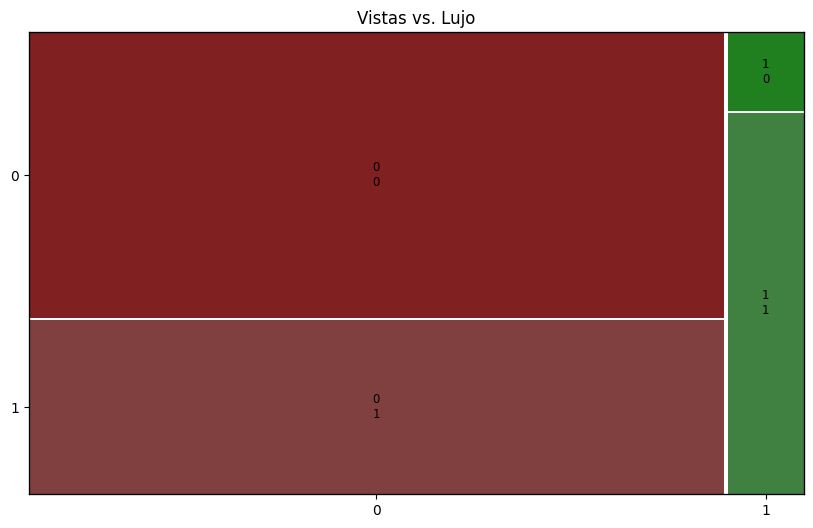

In [20]:
from statsmodels.graphics.mosaicplot import mosaic

plt.clf()
#mosaic(pd.crosstab(vinosDep.Clasificacion, varObjBin))
mosaic(viviendasDep,['view','Luxury'],gap=0.005, title='Vistas vs. Lujo')
#sns.heatmap(pd.crosstab(vinosDep.Etiqueta, varObjBin))
plt.show()


Si se quiesiera tratar floors como categórica habria que mirar...



<Figure size 1000x600 with 0 Axes>

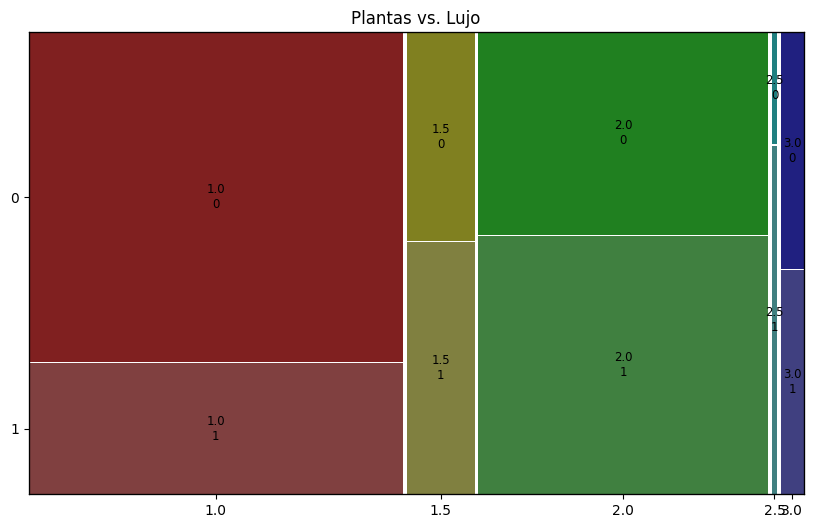

In [22]:
plt.clf()
mosaic(viviendasDep,['floors','Luxury'],gap=0.005, title='Plantas vs. Lujo')
#sns.heatmap(pd.crosstab(viviendasDep.floors, varObjBin))
plt.show()


Mala pinta floors con esa categoría 3.5....



In [23]:
pd.crosstab(viviendasDep.floors, varObjBin)



Luxury,0,1
floors,,
1.0,1762,701
1.5,202,244
2.0,837,1068
2.5,9,28
3.0,76,72


Problema! Categoría con 1 vivienda...unimos claramente a 3. Incluso ese 9 creo que dará problemas para las métricas en generarización por CV..seguramente aporte mucha varianza! Sintiéndolo mucho por ese efecto que parecía potente de 2.5 y no tanto en 3, si la trato como nominal uno a partir de 2,5. Se puede comprobar que la mejora de resultados es notable.



In [24]:
# Unimos la categorías problemáticas de floors en archivo original
viviendasDep['floors_cat'] = viviendasDep.floors.replace([2.5,3.0,3.5],'2.5+',inplace=False).astype('category')

# Unimos la categorías problemáticas de floors en el input de predictores
inputDep['floors_cat'] = inputDep.floors.replace([2.5,3.0,3.5],'2.5+',inplace=False).astype('category')


Así nos podemos entretener todo lo que queramos!

# Transformaciones de variables

Vamos a generar las transformaciones de las variable continuas que maximizan la relación con la variable objetivo binaria en sentido de V de Cramer.

**Nota 1:** La principal precaución que hay que tener si utilizamos el arvhivo tod_bin es no considerar un modelo completo con todas al mismo tiempo puesto que se pueden generar los problemas de colinealidad. Solamente utilizaremos el set completo de variables cuando hagamos un proceso de selección automática de variables, proceso en el cual se elegirán las que más R2 aporten al modelo.

**Nota 2:** Detallito de parte de python...no nos permite calcular exponencial de más de unos 710...por el tipo float64 que no admite números grandes..bueno, limitaciones de rendimiento. Esto en ppio no nos agrada, la escala de medida de algunas de nuestras variables excede ese límite y quisiéramos poder valorar el efecto de las transformaciones. Lo que podemos hacer es un estandarizado previo, luego la traslación a positivo y luego transformar. Cuidado con esto a la hora de 1) generar predicciones en un posible test que no esté transformado. Habría que aplicar exactamente la transformación igual (scale+traslación+transformación ganadora en sí). 2) interpretar el parámetro del modelo (aumento unitario de la variable escalada, trasladada y transformada..)


In [25]:
# Aplicar la función mejor transofrmación a sqft living por ejemplo
tr = mejorTransf(viviendasDep.sqft_living,varObjBin, tipo='cramer', graf=True)
tr.head()


,sqft_living_ident
0,1.903155
1,1.421794
2,3.750239
3,2.115850
4,1.880767


La mejor variable es la original!

Vamos a aplicar masivamente las transformaciones, pero vamos a quitar los aleatorios y las superficies totales y log total pues ya tiene su transformación.

De hecho, creo que vamos a eliminar directamente sqft_lot original porque no vale para nada con tanta asimentría!

In [26]:
# Aplicar a las variables continuas la mejor transformación según cramer frente a varObjBin
transf_cramer = inputDep.drop(['aleatorio','aleatorio2','log_sqft_lot'],axis=1).select_dtypes(include=np.number).apply(lambda x: mejorTransf(x,varObjBin, tipo='cramer', graf=False))
transf_cramer_names = inputDep.drop(['aleatorio','aleatorio2','log_sqft_lot'],axis=1).select_dtypes(include=np.number).apply(lambda x: mejorTransf(x,varObjBin,tipo='cramer', name=True))
transf_cramer.columns = transf_cramer_names.values
transf_cramer.head()


,month_raiz4,bathrooms_ident,sqft_living_ident,sqft_above_ident,yr_built_ident,lat_sqr,long_log,bedrooms_cont_ident,prop_missings_ident,floors_ident
0,1.177619,2.882919,1.903155,1.440745,2.737291,10.029352,1.253926,3.334081,3.195691,0.000100
1,1.125150,1.729791,1.421794,1.440745,0.547538,13.429967,0.248454,2.222754,3.195691,0.924691
2,1.303244,4.036046,3.750239,4.125024,3.661093,1.437506,1.392269,4.445409,3.195691,0.000100
3,1.370290,4.036046,2.115850,1.859394,3.524233,12.380140,0.025330,3.334081,3.195691,1.849282
4,1.303244,2.306355,1.880767,0.985156,2.052993,18.148817,0.231648,3.334081,3.195691,0.000100


In [27]:
# Generar input con transformaciones
input_transf = inputDep.join(transf_cramer)

# Aplicar la función al input completo contra la objetivo
tablaCramer = pd.DataFrame(input_transf.apply(lambda x: cramers_v(x,varObjBin)),columns=['VCramer'])
tablaCramer
# Obtener el gráfico de importancia de las variables frente a la objetivo continua según vcramer
import plotly.express as px
px.bar(tablaCramer,x=tablaCramer.VCramer,title='Relaciones frente a Luxury').update_yaxes(categoryorder="total ascending").show()


En algunas ocasiones se ha seleccionado la identidad como transformada. Mejor eliminar estas para no cargar el dataset.



In [29]:
# Eliminar toda columna que contenga _ident en el nombre
input_transf = input_transf.loc[:,~input_transf.columns.str.contains('_ident', case=False)]
# O bien --> input_transf.drop(input_transf.columns[input_transf.columns.str.contains('_ident')], axis=1, inplace=True)
input_transf.info()


<class 'pandas.core.frame.DataFrame'>
Index: 4999 entries, 0 to 4998
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   month          4999 non-null   float64 
 1   bathrooms      4999 non-null   float64 
 2   sqft_living    4999 non-null   float64 
 3   sqft_above     4999 non-null   float64 
 4   yr_built       4999 non-null   float64 
 5   lat            4999 non-null   float64 
 6   long           4999 non-null   float64 
 7   bedrooms_cont  4999 non-null   float64 
 8   log_sqft_lot   4999 non-null   float64 
 9   prop_missings  4999 non-null   float64 
 10  year           4999 non-null   category
 11  floors         4999 non-null   float64 
 12  waterfront     4999 non-null   category
 13  view           4999 non-null   category
 14  condition      4999 non-null   category
 15  basement       4999 non-null   category
 16  yr_renovated   4999 non-null   category
 17  bedrooms_cat   4999 non-null   categor

# Analisis exploratorio de modelos con el método train/test

Vamos a probar modelos manuales con el archivo que contiene las transformaciones para contrastar los efectos.



**Métricas de ajuste en training-test**

Nos venimos totalmente arriba y creamos una función para minimizar nuestra picada de código en esquemas tr-tst repetitivos con multitud de modelos. La idea es que dada una fórmula y un data completo (al natural y no matrices de diseño) nos devuelva un pequeño reporte de ajuste con cosas como el accuracy en training, matriz de confusión y métricas en test y AUC.

Con esta función, podemos permitirnos el lujo de no tomar la partición training-test e ir arrastrando objetos en nuestro análisis. Por contra, vamos a ajustar modelos en datos completos y luego le pedimos reporte en training-test recurriendo a la función que crea la partición por nosotros y prueba los ajustes/capacidad de generalización.

## Modelo completo de referencia

Vamos a hacer una comparativa inicial de los modelos completos con efectos originales y con efectos transformados. Por supuesto, alerta de no incluir ambos efectos a la vez en ningún modelo!!


In [30]:

data_transf = input_transf.join(varObjBin.astype('int64'))
# Aplicamos a fórmula de modelo completo y modelo completo con efectos transformados
formC_transf=ols_formula(data_transf,'Luxury','month','bedrooms_cat','lat','long','floors_cat','floors')
print(formC_transf)

data_orig = inputDep.join(varObjBin.astype('int64'))
# Aplicamos a fórmula de modelo completo y modelo completo con efectos originales
formC=ols_formula(data_orig,'Luxury','bedrooms_cat','floors_cat' )
print(formC)


Luxury ~ bathrooms + sqft_living + sqft_above + yr_built + bedrooms_cont + log_sqft_lot + prop_missings + year + waterfront + view + condition + basement + yr_renovated + aleatorio + aleatorio2 + month_raiz4 + lat_sqr + long_log
Luxury ~ month + bathrooms + sqft_living + sqft_above + yr_built + lat + long + bedrooms_cont + log_sqft_lot + prop_missings + year + floors + waterfront + view + condition + basement + yr_renovated + aleatorio + aleatorio2


**Modelos completo con Efectos originales**



In [31]:
# Importamos la api para fórmulas (en concreto ols para regresión)
from statsmodels.formula.api import logit

# Ajusto regresión modelo completo efectos ppales
modeloCompleto = logit(formC,data=data_orig).fit()
modeloCompleto.summary()



Optimization terminated successfully.
         Current function value: 0.375971
         Iterations 8


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                 Luxury   No. Observations:                 4999
Model:                          Logit   Df Residuals:                     4977
Method:                           MLE   Df Model:                           21
Date:                Sat, 24 Jan 2026   Pseudo R-squ.:                  0.4480
Time:                        08:44:50   Log-Likelihood:                -1879.5
converged:                       True   LL-Null:                       -3405.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
=====================================================================================
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept          -305.2780     50.169     -6.085      0.000    -403.607    -206.949
year[T.2015]          0.3429      0.140      2.458      0.014       0.069       0.616
waterfront[T.1]       1.7876      0.685      2.610      0.009       0.445       3.130
view[T.1]             1.7161      0.174      9.859      0.000       1.375       2.057
condition[T.A]        0.7446      0.567      1.313      0.189      -0.367       1.856
condition[T.B]        0.3075      0.551      0.558      0.577      -0.773       1.388
condition[T.CD]       0.5154      0.553      0.932      0.351      -0.568       1.599
basement[T.1]         0.6897      0.167      4.141      0.000       0.363       1.016
yr_renovated[T.1]    -0.0303      0.233     -0.130      0.897      -0.487       0.427
month                -0.0032      0.021     -0.151      0.880      -0.044       0.038
bathrooms             0.3008      0.074      4.079      0.000       0.156       0.445
sqft_living           0.0014      0.000      6.990      0.000       0.001       0.002
sqft_above            0.0013      0.000      5.830      0.000       0.001       0.002
yr_built             -0.0230      0.002    -10.710      0.000      -0.027      -0.019
lat                   8.5016      0.377     22.570      0.000       7.763       9.240
long                  0.4841      0.372      1.301      0.193      -0.245       1.213
bedrooms_cont        -0.3170      0.060     -5.269      0.000      -0.435      -0.199
log_sqft_lot         -0.1735      0.068     -2.565      0.010      -0.306      -0.041
prop_missings         0.0175      0.022      0.798      0.425      -0.025       0.060
floors                0.5910      0.114      5.200      0.000       0.368       0.814
aleatorio            -0.1074      0.141     -0.759      0.448      -0.385       0.170
aleatorio2           -0.1685      0.141     -1.196      0.232      -0.445       0.108
=====================================================================================
"""

Modelo que no tiene mala pinta inicialmente (evidentemente sobran efectos) porque los aleatorios y prop_missings no resultan significativos, pero a la vez hay muchos efectos que parecen significativos.

Veamos el ajuste en training y capacidad hacia test.

In [32]:
# Aplicar evaluación tr/test
tr_tst_eval_log(formC,data =data_orig)

Accuracy en training:  0.8207051762940735 

Matriz de confusión y métricas derivadas: 
 [[500  78]
 [115 307]]
              precision    recall  f1-score   support

         0.0       0.81      0.87      0.84       578
         1.0       0.80      0.73      0.76       422

    accuracy                           0.81      1000
   macro avg       0.81      0.80      0.80      1000
weighted avg       0.81      0.81      0.81      1000

Area bajo la curva ROC training: 
 0.9074517247493357
Area bajo la curva ROC test: 
 0.9011995933026123


Modelo con 81% de accuracy en training y también en test. Buenos valores de AUC. Algo de descompensación en sensibilidad (73%) y especificidad (87%). Seguramente quisiéramos mover el punto de corte de la probabilidad estimada para nuestras predicciones...

**Modelos completo con Efectos transformados**



In [33]:
# Ajusto regresión con fórmula completa y transformaciones
modeloCompleto_transf = logit(formC_transf,data=data_transf).fit()
modeloCompleto_transf.summary()


Optimization terminated successfully.
         Current function value: 0.395338
         Iterations 7


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                 Luxury   No. Observations:                 4999
Model:                          Logit   Df Residuals:                     4978
Method:                           MLE   Df Model:                           20
Date:                Sat, 24 Jan 2026   Pseudo R-squ.:                  0.4196
Time:                        08:48:40   Log-Likelihood:                -1976.3
converged:                       True   LL-Null:                       -3405.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
=====================================================================================
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            35.8985      4.068      8.825      0.000      27.926      43.871
year[T.2015]          0.5387      0.123      4.364      0.000       0.297       0.781
waterfront[T.1]       1.5454      0.667      2.317      0.021       0.238       2.853
view[T.1]             1.6602      0.169      9.847      0.000       1.330       1.991
condition[T.A]        0.5649      0.565      0.999      0.318      -0.543       1.673
condition[T.B]        0.1800      0.551      0.327      0.744      -0.900       1.260
condition[T.CD]       0.3385      0.552      0.613      0.540      -0.743       1.420
basement[T.1]         0.6590      0.163      4.042      0.000       0.339       0.978
yr_renovated[T.1]     0.0263      0.223      0.118      0.906      -0.412       0.464
bathrooms             0.3602      0.072      5.009      0.000       0.219       0.501
sqft_living           0.0013      0.000      6.398      0.000       0.001       0.002
sqft_above            0.0016      0.000      7.455      0.000       0.001       0.002
yr_built             -0.0209      0.002    -10.330      0.000      -0.025      -0.017
bedrooms_cont        -0.3206      0.059     -5.462      0.000      -0.436      -0.206
log_sqft_lot         -0.3515      0.059     -5.925      0.000      -0.468      -0.235
prop_missings         0.0161      0.021      0.752      0.452      -0.026       0.058
aleatorio            -0.0901      0.138     -0.654      0.513      -0.360       0.180
aleatorio2           -0.1297      0.137     -0.944      0.345      -0.399       0.140
month_raiz4           0.4741      0.215      2.202      0.028       0.052       0.896
lat_sqr               0.1702      0.008     20.703      0.000       0.154       0.186
long_log             -0.0029      0.098     -0.030      0.976      -0.195       0.189
=====================================================================================
"""

Empeora un poco el ajuste en trianing...habrá que ver en el test. Llama la atención el cambio en la significación de month!

In [34]:
tr_tst_eval_log(formC_transf,data =data_transf)


Accuracy en training:  0.8047011752938235 

Matriz de confusión y métricas derivadas: 
 [[494  84]
 [121 301]]
              precision    recall  f1-score   support

         0.0       0.80      0.85      0.83       578
         1.0       0.78      0.71      0.75       422

    accuracy                           0.80      1000
   macro avg       0.79      0.78      0.79      1000
weighted avg       0.79      0.80      0.79      1000

Area bajo la curva ROC training: 
 0.896286487644344
Area bajo la curva ROC test: 
 0.8876539464405778


En el proceso de modelado, partiendo de un modelo de regresión lineal completo con todas las variables originales, se valora el pseudo R o métricas como accuracy o AUC y nuestro objetivo será simplificar el modelo al máximo sin perder mucha precisión. Para ello:

-   Hacia delante: Empezar con las variables que parecen más relevantes en el análisis descriptivo y en el propio modelo. Una a una, viendo el posible efecto de interacción o confusión entre ellas (si al introducir una variable, el parámetro de una ya existente cambia significativamente, es posible que exista efecto conjunto)... Añadiremos efectos hasta que no se produzca mejora en las métricas (r2, AIC,BIC..)

-   Hacia atras: Se van eliminando paulatinamente efectos no significativos en el modelo (teniendo en cuenta la información del estudio descriptivo), evaluando los cambios producidos en parámetros hasta llegar a una disminución significativa de las métricas de evaluación (r2, AIC,BIC..)

Es conveniente repetir el proceso con las variables continuas transformadas.

Seguiremos un proceso hacia delante con el órden inicial dado por Cramer.

## Proceso manual con variables originales y algunas transformaciones

Vamos a probar modelos manuales hacia delante con los efectos principales y algunas transformaciones de las variables importantes


In [35]:
form1 = 'Luxury ~ sqft_living' # invito a probar otras superficies y combinaciones varias sin ganancia visible..log_sqft_lot y sqft_above

# Ajustar modelo 1
modelo1 = logit(form1,data=data_orig).fit()
modelo1.summary()



Optimization terminated successfully.
         Current function value: 0.500105
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                 Luxury   No. Observations:                 4999
Model:                          Logit   Df Residuals:                     4997
Method:                           MLE   Df Model:                            1
Date:                Sat, 24 Jan 2026   Pseudo R-squ.:                  0.2658
Time:                        08:52:20   Log-Likelihood:                -2500.0
converged:                       True   LL-Null:                       -3405.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
===============================================================================
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -4.1752      0.121    -34.426      0.000      -4.413      -3.937
sqft_living     0.0019   5.67e-05     32.898      0.000       0.002       0.002
===============================================================================
"""

In [36]:
tr_tst_eval_log(form1,data =data_orig)


Accuracy en training:  0.7594398599649912 

Matriz de confusión y métricas derivadas: 
 [[466 112]
 [158 264]]
              precision    recall  f1-score   support

         0.0       0.75      0.81      0.78       578
         1.0       0.70      0.63      0.66       422

    accuracy                           0.73      1000
   macro avg       0.72      0.72      0.72      1000
weighted avg       0.73      0.73      0.73      1000

Area bajo la curva ROC training: 
 0.8284160870015282
Area bajo la curva ROC test: 
 0.8119742042342446


In [37]:
# Añadimos lat pero en su transformada que parecía mejorar en Cramer (probar con lat original...sale parecido..)
form2 = 'Luxury ~ sqft_living+lat_sqr'

# Ajustar modelo 1
modelo1 = logit(form2,data=data_transf).fit()
modelo1.summary()




Optimization terminated successfully.
         Current function value: 0.440727
         Iterations 7


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                 Luxury   No. Observations:                 4999
Model:                          Logit   Df Residuals:                     4996
Method:                           MLE   Df Model:                            2
Date:                Sat, 24 Jan 2026   Pseudo R-squ.:                  0.3530
Time:                        08:58:49   Log-Likelihood:                -2203.2
converged:                       True   LL-Null:                       -3405.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
===============================================================================
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -6.2911      0.176    -35.745      0.000      -6.636      -5.946
sqft_living     0.0021   6.41e-05     32.648      0.000       0.002       0.002
lat_sqr         0.1663      0.007     22.301      0.000       0.152       0.181
===============================================================================
"""

In [38]:
tr_tst_eval_log(form2,data =data_transf)

Accuracy en training:  0.7849462365591398 

Matriz de confusión y métricas derivadas: 
 [[495  83]
 [129 293]]
              precision    recall  f1-score   support

         0.0       0.79      0.86      0.82       578
         1.0       0.78      0.69      0.73       422

    accuracy                           0.79      1000
   macro avg       0.79      0.78      0.78      1000
weighted avg       0.79      0.79      0.79      1000

Area bajo la curva ROC training: 
 0.874382370937177
Area bajo la curva ROC test: 
 0.8638445202446745


Introducimos ahora esa interacción que parecía interesante en la exploración de relaciones a priori entre sqft_living y lat.



In [39]:
form3 = 'Luxury ~ sqft_living*lat_sqr'

# Ajustar modelo 1
modelo1 = logit(form3,data=data_transf).fit()
modelo1.summary()



Optimization terminated successfully.
         Current function value: 0.436566
         Iterations 7


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                 Luxury   No. Observations:                 4999
Model:                          Logit   Df Residuals:                     4995
Method:                           MLE   Df Model:                            3
Date:                Sat, 24 Jan 2026   Pseudo R-squ.:                  0.3591
Time:                        09:00:31   Log-Likelihood:                -2182.4
converged:                       True   LL-Null:                       -3405.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
=======================================================================================
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -4.7645      0.280    -17.041      0.000      -5.313      -4.217
sqft_living             0.0014      0.000     10.960      0.000       0.001       0.002
lat_sqr                 0.0116      0.025      0.465      0.642      -0.037       0.061
sqft_living:lat_sqr  7.816e-05   1.22e-05      6.400      0.000    5.42e-05       0.000
=======================================================================================
"""

No notamos mejora con respecto al pseudo R2 del modelo pero si mejora un poquito la evaluación en training-test en cuanto a accuracy y curva roc.

Continuando con el proceso, ahora nos tocaría introducir la variable sqft_above con el problema de la colinealidad que posiblemente aporta al modelo... Habrá que ver...


In [40]:
tr_tst_eval_log(form3,data =data_transf)


Accuracy en training:  0.7964491122780695 

Matriz de confusión y métricas derivadas: 
 [[502  76]
 [125 297]]
              precision    recall  f1-score   support

         0.0       0.80      0.87      0.83       578
         1.0       0.80      0.70      0.75       422

    accuracy                           0.80      1000
   macro avg       0.80      0.79      0.79      1000
weighted avg       0.80      0.80      0.80      1000

Area bajo la curva ROC training: 
 0.8808799670392853
Area bajo la curva ROC test: 
 0.8728189212679776


In [41]:
form4 = 'Luxury ~ sqft_living*lat_sqr+sqft_above'

# Ajustar modelo 1
modelo1 = logit(form4,data=data_transf).fit()
modelo1.summary()



Optimization terminated successfully.
         Current function value: 0.436270
         Iterations 7


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                 Luxury   No. Observations:                 4999
Model:                          Logit   Df Residuals:                     4994
Method:                           MLE   Df Model:                            4
Date:                Sat, 24 Jan 2026   Pseudo R-squ.:                  0.3595
Time:                        09:03:24   Log-Likelihood:                -2180.9
converged:                       True   LL-Null:                       -3405.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
=======================================================================================
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -4.7645      0.279    -17.061      0.000      -5.312      -4.217
sqft_living             0.0012      0.000      7.919      0.000       0.001       0.002
lat_sqr                 0.0083      0.025      0.333      0.739      -0.041       0.057
sqft_living:lat_sqr   8.07e-05   1.23e-05      6.546      0.000    5.65e-05       0.000
sqft_above              0.0002   9.92e-05      1.716      0.086   -2.42e-05       0.000
=======================================================================================
"""

In [43]:
tr_tst_eval_log(form4,data =data_transf)


Accuracy en training:  0.7974493623405852 

Matriz de confusión y métricas derivadas: 
 [[505  73]
 [128 294]]
              precision    recall  f1-score   support

         0.0       0.80      0.87      0.83       578
         1.0       0.80      0.70      0.75       422

    accuracy                           0.80      1000
   macro avg       0.80      0.79      0.79      1000
weighted avg       0.80      0.80      0.80      1000

Area bajo la curva ROC training: 
 0.8809109701990455
Area bajo la curva ROC test: 
 0.8733354925466144


El contraste sobre el parámetro está justito...las métricas no mejoran sustancialemnte. Podríamos intuir que esta combinación no aporta gran ganancia en capacidad predictiva al menos en training-test. Guardaremos el modelo para CV.

Probamos a introducir floors.


In [44]:
form5 = 'Luxury ~ sqft_living+lat_sqr+floors' #bedrooms_cont+view+waterfront+basement

# Ajustar modelo 1
modelo1 = logit(form5,data=data_transf).fit()
print(modelo1.summary())

tr_tst_eval_log(form5,data =data_transf)


Optimization terminated successfully.
         Current function value: 0.438877
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                 Luxury   No. Observations:                 4999
Model:                          Logit   Df Residuals:                     4995
Method:                           MLE   Df Model:                            3
Date:                Sat, 24 Jan 2026   Pseudo R-squ.:                  0.3557
Time:                        09:05:53   Log-Likelihood:                -2193.9
converged:                       True   LL-Null:                       -3405.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -6.6524      0.199    -33.488      0.000      -7.042      -6.263
sqft_living     0.0020   6

No parece que el modelo mejore...

Añadimos algunas variables relevantes más.


In [45]:
form6 = 'Luxury ~ sqft_living+lat_sqr+floors+bedrooms_cont+view+waterfront'

# Ajustar modelo 1
modelo1 = logit(form6,data=data_transf).fit()
modelo1.summary()



Optimization terminated successfully.
         Current function value: 0.419013
         Iterations 7


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                 Luxury   No. Observations:                 4999
Model:                          Logit   Df Residuals:                     4992
Method:                           MLE   Df Model:                            6
Date:                Sat, 24 Jan 2026   Pseudo R-squ.:                  0.3848
Time:                        09:09:29   Log-Likelihood:                -2094.6
converged:                       True   LL-Null:                       -3405.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
===================================================================================
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          -6.4807      0.230    -28.204      0.000      -6.931      -6.030
view[T.1]           1.7669      0.160     11.031      0.000       1.453       2.081
waterfront[T.1]     1.4696      0.654      2.246      0.025       0.187       2.752
sqft_living         0.0022   8.12e-05     26.553      0.000       0.002       0.002
lat_sqr             0.1779      0.008     22.777      0.000       0.163       0.193
floors              0.3646      0.070      5.184      0.000       0.227       0.502
bedrooms_cont      -0.2268      0.056     -4.045      0.000      -0.337      -0.117
===================================================================================
"""

In [46]:
tr_tst_eval_log(form6,data =data_transf)


Accuracy en training:  0.7999499874968742 

Matriz de confusión y métricas derivadas: 
 [[497  81]
 [117 305]]
              precision    recall  f1-score   support

         0.0       0.81      0.86      0.83       578
         1.0       0.79      0.72      0.75       422

    accuracy                           0.80      1000
   macro avg       0.80      0.79      0.79      1000
weighted avg       0.80      0.80      0.80      1000

Area bajo la curva ROC training: 
 0.8853041948043828
Area bajo la curva ROC test: 
 0.8809610685645879


De nuevo, no encontramos ganancia que justifique el aumento paramétrico, si bien el modelo parece bueno en cuanto al contraste paramétrico.



In [48]:
form62 = 'Luxury ~ sqft_living+lat_sqr+floors+bedrooms_cont+view'

# Ajustar modelo 1
modelo1 = logit(form62,data=data_transf).fit()
modelo1.summary()


Optimization terminated successfully.
         Current function value: 0.419617
         Iterations 7


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                 Luxury   No. Observations:                 4999
Model:                          Logit   Df Residuals:                     4993
Method:                           MLE   Df Model:                            5
Date:                Sat, 24 Jan 2026   Pseudo R-squ.:                  0.3840
Time:                        09:13:11   Log-Likelihood:                -2097.7
converged:                       True   LL-Null:                       -3405.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
=================================================================================
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -6.4508      0.229    -28.177      0.000      -6.899      -6.002
view[T.1]         1.8692      0.156     11.960      0.000       1.563       2.176
sqft_living       0.0022   8.12e-05     26.579      0.000       0.002       0.002
lat_sqr           0.1770      0.008     22.715      0.000       0.162       0.192
floors            0.3625      0.070      5.158      0.000       0.225       0.500
bedrooms_cont    -0.2327      0.056     -4.158      0.000      -0.342      -0.123
=================================================================================
"""

In [50]:
tr_tst_eval_log(form62,data =data_transf)


Accuracy en training:  0.7986996749187297 

Matriz de confusión y métricas derivadas: 
 [[497  81]
 [119 303]]
              precision    recall  f1-score   support

         0.0       0.81      0.86      0.83       578
         1.0       0.79      0.72      0.75       422

    accuracy                           0.80      1000
   macro avg       0.80      0.79      0.79      1000
weighted avg       0.80      0.80      0.80      1000

Area bajo la curva ROC training: 
 0.8849846829017319
Area bajo la curva ROC test: 
 0.8806289870283213


In [51]:
form63 = 'Luxury ~ sqft_living+lat+floors+bedrooms_cont+view+bathrooms+year+yr_built+month_raiz4'
#form63 = 'Luxury ~ month_raiz4 + bathrooms + sqft_living  + yr_built + lat_sqr  + bedrooms_cont + year + floors + view'

# Ajustar modelo 1
modelo1 = logit(form63,data=data_transf).fit()
print(modelo1.summary())

tr_tst_eval_log(form63,data =data_transf)


Optimization terminated successfully.
         Current function value: 0.380861
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:                 Luxury   No. Observations:                 4999
Model:                          Logit   Df Residuals:                     4989
Method:                           MLE   Df Model:                            9
Date:                Sat, 24 Jan 2026   Pseudo R-squ.:                  0.4409
Time:                        09:14:03   Log-Likelihood:                -1903.9
converged:                       True   LL-Null:                       -3405.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept      -356.8353     17.804    -20.043      0.000    -391.730    -321.940
view[T.1]         1.

## Comparación manuales por CV

Vamos a comparar estos modelos manuales por CV para valorar su capacidad de generalización.


In [56]:

form64 = 'Luxury ~ sqft_living+lat+floors+bedrooms_cont+view+bathrooms+year+yr_built'
form65 = 'Luxury ~ sqft_living+lat_sqr+floors+bedrooms_cont+view+bathrooms+year+yr_built'
form66 = 'Luxury ~ sqft_living+lat_sqr+floors+bedrooms_cont+view+bathrooms+year+yr_built+sqft_above'
# Creamos lista de fórmulas
list_form = [formC,form1,form2,form3,form4,form5,form6,form62,form63,form64,form65,form66]
list_form


# Aplicamos a toda la lista la función creada (devuelve un dataframe pero está transpuesto)
list_res = pd.DataFrame(map(lambda x: cross_val_log(x,data_transf, seed=2023),list_form))


Modelo: Luxury ~ month + bathrooms + sqft_living + sqft_above + yr_built + lat + long + bedrooms_cont + log_sqft_lot + prop_missings + year + floors + waterfront + view + condition + basement + yr_renovated + aleatorio + aleatorio2
AUC: 0.899 (0.010)
Modelo: Luxury ~ sqft_living
AUC: 0.825 (0.012)
Modelo: Luxury ~ sqft_living+lat_sqr
AUC: 0.872 (0.011)
Modelo: Luxury ~ sqft_living*lat_sqr
AUC: 0.880 (0.010)
Modelo: Luxury ~ sqft_living*lat_sqr+sqft_above
AUC: 0.880 (0.010)
Modelo: Luxury ~ sqft_living+lat_sqr+floors
AUC: 0.872 (0.011)
Modelo: Luxury ~ sqft_living+lat_sqr+floors+bedrooms_cont+view+waterfront
AUC: 0.884 (0.010)
Modelo: Luxury ~ sqft_living+lat_sqr+floors+bedrooms_cont+view
AUC: 0.884 (0.010)
Modelo: Luxury ~ sqft_living+lat+floors+bedrooms_cont+view+bathrooms+year+yr_built+month_raiz4
AUC: 0.882 (0.012)
Modelo: Luxury ~ sqft_living+lat+floors+bedrooms_cont+view+bathrooms+year+yr_built
AUC: 0.902 (0.011)
Modelo: Luxury ~ sqft_living+lat_sqr+floors+bedrooms_cont+view+bathr

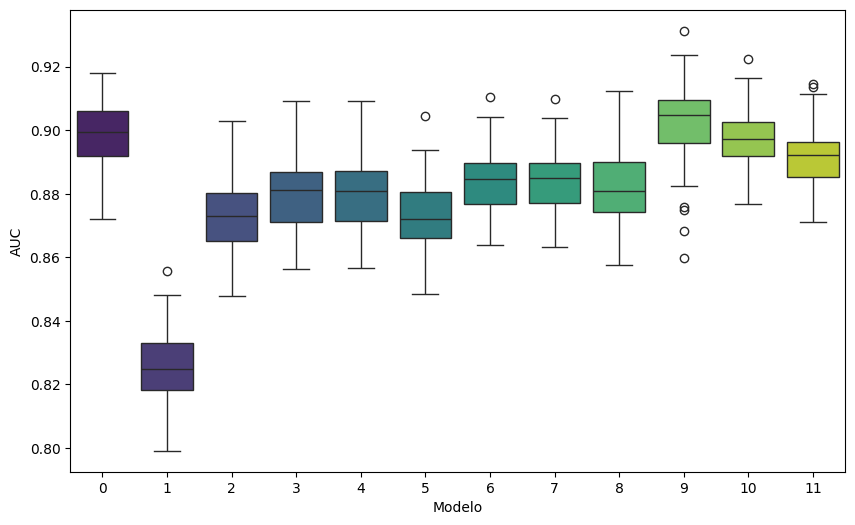

In [57]:
# Trasnponer dataframe y pasar de wide a long (creando un factor variable con el nombre de cada fórmula de la lista[0,1,2,3])
results = list_res.T.melt()
results.columns = ['Modelo','AUC']
results.head()

# Boxplot paralelo para comparar
plt.clf()
sns.boxplot(x='Modelo',y='AUC',data=results,palette='viridis')
plt.show()


El penultimo modelo es el que mejor comportamiento tiene por menor variabilidad. Por otra parte se observa gran variabilidad de las predicciones en CV, síntoma de robustez regulera de los modelos...Quizá esa Lat está causando estragos por un efecto lineal muy distinto según la muestra escogida... Visto esto vamos a tratar de jugar un poco con las superficies (por si hubiera cierta interacción entre ellas) y tramificar Lat por el tema de robustez..


## Posibilidades opcionales. Juegos con las superficies

Vamos a crear el ratio y la suma de superficies para tener un solo efecto conjunto de ambas variables y evitar la colinealidad. Valoraremos si estas transformaciones recogen el efecto sobre la variable objetivo.


In [58]:
data_orig['sqft_ratio'] = data_orig.sqft_living/data_orig.sqft_above
data_transf['sqft_ratio'] = data_transf.sqft_living/data_transf.sqft_above

data_orig['sqft_sum'] = data_orig.sqft_living+data_orig.sqft_above
data_transf['sqft_sum'] = data_transf.sqft_living+data_transf.sqft_above


Modelo con la suma interaccionando con lat



In [59]:
form7 = 'Luxury ~ sqft_sum+lat_sqr+floors+bedrooms_cont+view+yr_built+bathrooms+year+yr_built'

# Ajustar modelo 1
modelo1 = logit(form7,data=data_transf).fit()
modelo1.summary()



Optimization terminated successfully.
         Current function value: 0.403429
         Iterations 7


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                 Luxury   No. Observations:                 4999
Model:                          Logit   Df Residuals:                     4990
Method:                           MLE   Df Model:                            8
Date:                Sat, 24 Jan 2026   Pseudo R-squ.:                  0.4077
Time:                        10:12:13   Log-Likelihood:                -2016.7
converged:                       True   LL-Null:                       -3405.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
=================================================================================
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        43.4455      3.402     12.771      0.000      36.778      50.113
view[T.1]         1.8823      0.158     11.921      0.000       1.573       2.192
year[T.2015]      0.3037      0.084      3.605      0.000       0.139       0.469
sqft_sum          0.0012   4.86e-05     24.669      0.000       0.001       0.001
lat_sqr           0.1745      0.008     21.633      0.000       0.159       0.190
floors            0.4196      0.087      4.819      0.000       0.249       0.590
bedrooms_cont    -0.2346      0.056     -4.170      0.000      -0.345      -0.124
yr_built         -0.0260      0.002    -14.577      0.000      -0.030      -0.023
bathrooms         0.5024      0.069      7.298      0.000       0.367       0.637
=================================================================================
"""

In [60]:
tr_tst_eval_log(form7,data =data_transf)


Accuracy en training:  0.8072018004501126 

Matriz de confusión y métricas derivadas: 
 [[500  78]
 [117 305]]
              precision    recall  f1-score   support

         0.0       0.81      0.87      0.84       578
         1.0       0.80      0.72      0.76       422

    accuracy                           0.81      1000
   macro avg       0.80      0.79      0.80      1000
weighted avg       0.80      0.81      0.80      1000

Area bajo la curva ROC training: 
 0.8958373261645146
Area bajo la curva ROC test: 
 0.8898391249446532


Aquí nos hemos planteado tramificar sqft_above para tratar de ganar capacidad y reducir o eliminar la colinealidad posible con sqft_living sin mucho éxito (probad!). Siguiente alternativa que se nos ocurre es tramificar la variable Lat porque interacciona con sqft_living y además parece tener un parámetro muy grande por aumento unitario con una tendencia lineal que tal vez no se está compliendo... Quizá ganemos explicabilidad partiendo la variable en los dos tramos que hemos observado en el scatter de la primera parte.

**Tramificar Lat**


In [63]:
# http://gnpalencia.org/optbinning/binning_continuous.html
!pip install optbinning


In [64]:
from optbinning import ContinuousOptimalBinning

optb = ContinuousOptimalBinning(name='lat', dtype="numerical", max_n_bins=2)
optb.fit(inputDep['lat'].values, varObjBin)

x_transform_bins = optb.transform(inputDep['lat'].values, metric="bins")
x_transform_bins

array(['[47.53, inf)', '[47.53, inf)', '(-inf, 47.53)', ...,
       '(-inf, 47.53)', '[47.53, inf)', '[47.53, inf)'], dtype=object)

Introducimos la nueva variable en los datasets que manejaremos y por supuesto volvemos a tirar la partición!!



In [65]:
# Incluimos la tramificación en data original y transformado
data_orig['lat_rec'] = x_transform_bins
data_transf['lat_rec'] = x_transform_bins


## Modelos manuales con Lat tramificada



In [66]:
form8 = 'Luxury ~ sqft_living+lat_rec'

# Ajustar modelo 1
modelo1 = logit(form8,data=data_transf).fit()
print(modelo1.summary())

tr_tst_eval_log(form8,data =data_transf)


Optimization terminated successfully.
         Current function value: 0.376040
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                 Luxury   No. Observations:                 4999
Model:                          Logit   Df Residuals:                     4996
Method:                           MLE   Df Model:                            2
Date:                Sat, 24 Jan 2026   Pseudo R-squ.:                  0.4479
Time:                        10:13:46   Log-Likelihood:                -1879.8
converged:                       True   LL-Null:                       -3405.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                  -7.3225      0.207    -35.318      0.000      -7.729   

Me planteo introducir efecto doble de Lat en dos tramos + lat transformada. Elgo así como un efecto no lineal con tendencias distintas en dos "barrios".

Flipante la capacidad predictiva que hemos ganado con esta tramificación!!!


In [67]:
form9 = 'Luxury ~ sqft_living+lat_rec+lat_sqr'

# Ajustar modelo 1
modelo1 = logit(form9,data=data_transf).fit()
modelo1.summary()



Optimization terminated successfully.
         Current function value: 0.370881
         Iterations 7


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                 Luxury   No. Observations:                 4999
Model:                          Logit   Df Residuals:                     4995
Method:                           MLE   Df Model:                            3
Date:                Sat, 24 Jan 2026   Pseudo R-squ.:                  0.4555
Time:                        10:13:48   Log-Likelihood:                -1854.0
converged:                       True   LL-Null:                       -3405.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
===========================================================================================
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                  -7.0340      0.210    -33.429      0.000      -7.446      -6.622
lat_rec[T.[47.53, inf)]     3.9960      0.170     23.528      0.000       3.663       4.329
sqft_living                 0.0024   7.61e-05     31.421      0.000       0.002       0.003
lat_sqr                    -0.0903      0.013     -7.122      0.000      -0.115      -0.065
===========================================================================================
"""

In [68]:
tr_tst_eval_log(form9,data =data_transf)


Accuracy en training:  0.8339584896224056 

Matriz de confusión y métricas derivadas: 
 [[514  64]
 [110 312]]
              precision    recall  f1-score   support

         0.0       0.82      0.89      0.86       578
         1.0       0.83      0.74      0.78       422

    accuracy                           0.83      1000
   macro avg       0.83      0.81      0.82      1000
weighted avg       0.83      0.83      0.82      1000

Area bajo la curva ROC training: 
 0.9132457284820136
Area bajo la curva ROC test: 
 0.9011196477475851


Introduciremos sqft_above para ver su influencia



In [69]:
form10 = 'Luxury ~ sqft_living+lat_rec+sqft_above'

# Ajustar modelo 1
modelo1 = logit(form10,data=data_transf).fit()
print(modelo1.summary())

tr_tst_eval_log(form10,data =data_transf)


Optimization terminated successfully.
         Current function value: 0.375252
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                 Luxury   No. Observations:                 4999
Model:                          Logit   Df Residuals:                     4995
Method:                           MLE   Df Model:                            3
Date:                Sat, 24 Jan 2026   Pseudo R-squ.:                  0.4491
Time:                        10:13:51   Log-Likelihood:                -1875.9
converged:                       True   LL-Null:                       -3405.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                  -7.4255      0.213    -34.905      0.000      -7.842   

Ahora recuperamos algunos modelos con más efectos para comparar.



In [70]:
form11 = 'Luxury ~ sqft_living+lat_rec+waterfront+view+floors+bedrooms_cont'

# Ajustar modelo 1
modelo1 = logit(form11,data=data_transf).fit()
modelo1.summary()

tr_tst_eval_log(form11,data =data_transf)


Optimization terminated successfully.
         Current function value: 0.353196
         Iterations 8
Accuracy en training:  0.8357089272318079 

Matriz de confusión y métricas derivadas: 
 [[510  68]
 [102 320]]
              precision    recall  f1-score   support

         0.0       0.83      0.88      0.86       578
         1.0       0.82      0.76      0.79       422

    accuracy                           0.83      1000
   macro avg       0.83      0.82      0.82      1000
weighted avg       0.83      0.83      0.83      1000

Area bajo la curva ROC training: 
 0.9200970424522936
Area bajo la curva ROC test: 
 0.9175084865281491


In [71]:
form12 = 'Luxury ~ sqft_living+lat_rec+waterfront+view+floors+bedrooms_cont+long_log'

# Ajustar modelo 1
modelo1 = logit(form12,data=data_transf).fit()
print(modelo1.summary())


tr_tst_eval_log(form12,data =data_transf)


Optimization terminated successfully.
         Current function value: 0.351233
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:                 Luxury   No. Observations:                 4999
Model:                          Logit   Df Residuals:                     4991
Method:                           MLE   Df Model:                            7
Date:                Sat, 24 Jan 2026   Pseudo R-squ.:                  0.4843
Time:                        10:13:54   Log-Likelihood:                -1755.8
converged:                       True   LL-Null:                       -3405.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                  -7.4760      0.265    -28.256      0.000      -7.995   

In [72]:
form13 = 'Luxury ~ sqft_living+lat_rec+waterfront+view+floors+bedrooms_cont+lat_sqr*long_log'

# Ajustar modelo 1
modelo1 = logit(form13,data=data_transf).fit()
modelo1.summary()

tr_tst_eval_log(form13,data =data_transf)


Optimization terminated successfully.
         Current function value: 0.345796
         Iterations 8
Accuracy en training:  0.8444611152788197 

Matriz de confusión y métricas derivadas: 
 [[517  61]
 [100 322]]
              precision    recall  f1-score   support

         0.0       0.84      0.89      0.87       578
         1.0       0.84      0.76      0.80       422

    accuracy                           0.84      1000
   macro avg       0.84      0.83      0.83      1000
weighted avg       0.84      0.84      0.84      1000

Area bajo la curva ROC training: 
 0.923978971146051
Area bajo la curva ROC test: 
 0.9213971203201101


Nuestro último intento manual consiste en cambiar sqft_living por la transformación suma de living+above en este último modelo para valorar si hay mejora al incluir el efecto conjunto de ambas variables evitando la colinealidad.



In [73]:
form14 = 'Luxury ~ sqft_sum+lat_rec+waterfront+view+floors+bedrooms_cont+lat_sqr*long_log'

# Ajustar modelo 1
modelo1 = logit(form14,data=data_transf).fit()
modelo1.summary()




Optimization terminated successfully.
         Current function value: 0.346156
         Iterations 8


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                 Luxury   No. Observations:                 4999
Model:                          Logit   Df Residuals:                     4989
Method:                           MLE   Df Model:                            9
Date:                Sat, 24 Jan 2026   Pseudo R-squ.:                  0.4918
Time:                        10:13:57   Log-Likelihood:                -1730.4
converged:                       True   LL-Null:                       -3405.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
===========================================================================================
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                  -7.5028      0.299    -25.091      0.000      -8.089      -6.917
lat_rec[T.[47.53, inf)]     4.5127      0.188     23.964      0.000       4.144       4.882
waterfront[T.1]             2.7361      0.661      4.138      0.000       1.440       4.032
view[T.1]                   2.0530      0.198     10.378      0.000       1.665       2.441
sqft_sum                    0.0015   5.75e-05     26.314      0.000       0.001       0.002
floors                     -0.2618      0.082     -3.181      0.001      -0.423      -0.101
bedrooms_cont              -0.1580      0.059     -2.677      0.007      -0.274      -0.042
lat_sqr                    -0.0510      0.016     -3.262      0.001      -0.082      -0.020
long_log                   -0.0476      0.176     -0.270      0.787      -0.393       0.298
lat_sqr:long_log           -0.0660      0.016     -4.121      0.000      -0.097      -0.035
===========================================================================================
"""

In [74]:
form15 = 'Luxury ~ sqft_living+lat_rec+floors+bedrooms_cont+view+yr_built+bathrooms+year+yr_built'

# Ajustar modelo 1
modelo1 = logit(form15,data=data_transf).fit()
print(modelo1.summary())

tr_tst_eval_log(form15,data =data_transf)


Optimization terminated successfully.
         Current function value: 0.342460
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:                 Luxury   No. Observations:                 4999
Model:                          Logit   Df Residuals:                     4990
Method:                           MLE   Df Model:                            8
Date:                Sat, 24 Jan 2026   Pseudo R-squ.:                  0.4972
Time:                        10:13:57   Log-Likelihood:                -1712.0
converged:                       True   LL-Null:                       -3405.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                  28.5667      3.637      7.855      0.000      21.439   

# Comparación final de mosdelos manuales por validación cruzada

Recogemos todos los modelos ajustados y los probamos por validación cruzada repetida para valorar las capacidades en relación a la simplicidad del modelo y seleccionar el modelo final.

Tenemos los modelos con lat al natural y luego los modelos con lat recodificada y alguno con la transformación suma de las superficies.


In [76]:
# Creamos lista de fórmulas
list_form = [formC,form1,form2,form3,form4,form5,form6,form62,form63,form64,form65,form66,form8,form9,form10,form11,form12,form13,form14,form15]
list_form


# Aplicamos a toda la lista la función creada (devuelve un dataframe pero está transpuesto)
list_res = pd.DataFrame(map(lambda x: cross_val_log(x,data_transf, seed=2023),list_form))


Modelo: Luxury ~ month + bathrooms + sqft_living + sqft_above + yr_built + lat + long + bedrooms_cont + log_sqft_lot + prop_missings + year + floors + waterfront + view + condition + basement + yr_renovated + aleatorio + aleatorio2
AUC: 0.899 (0.010)
Modelo: Luxury ~ sqft_living
AUC: 0.825 (0.012)
Modelo: Luxury ~ sqft_living+lat_sqr
AUC: 0.872 (0.011)
Modelo: Luxury ~ sqft_living*lat_sqr
AUC: 0.880 (0.010)
Modelo: Luxury ~ sqft_living*lat_sqr+sqft_above
AUC: 0.880 (0.010)
Modelo: Luxury ~ sqft_living+lat_sqr+floors
AUC: 0.872 (0.011)
Modelo: Luxury ~ sqft_living+lat_sqr+floors+bedrooms_cont+view+waterfront
AUC: 0.884 (0.010)
Modelo: Luxury ~ sqft_living+lat_sqr+floors+bedrooms_cont+view
AUC: 0.884 (0.010)
Modelo: Luxury ~ sqft_living+lat+floors+bedrooms_cont+view+bathrooms+year+yr_built+month_raiz4
AUC: 0.882 (0.012)
Modelo: Luxury ~ sqft_living+lat+floors+bedrooms_cont+view+bathrooms+year+yr_built
AUC: 0.902 (0.011)
Modelo: Luxury ~ sqft_living+lat_sqr+floors+bedrooms_cont+view+bathr

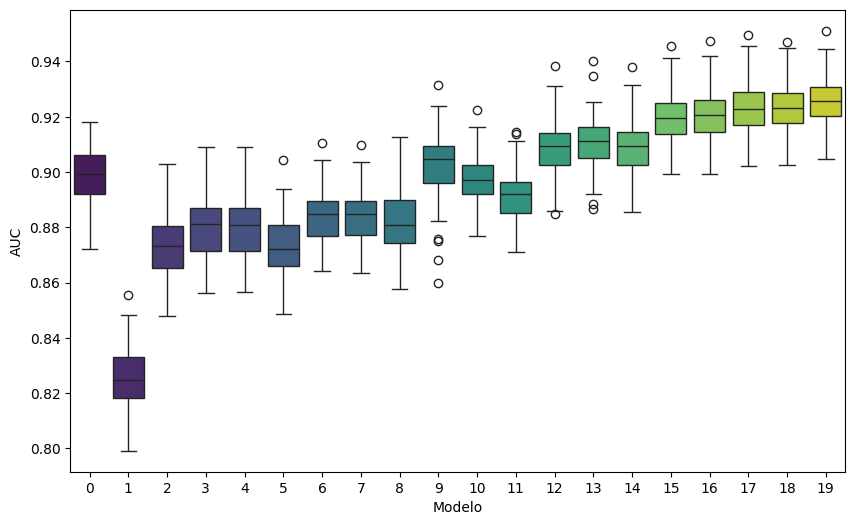

In [77]:
# Transponer dataframe y pasar de wide a long (creando un factor variable con el nombre de cada fórmula de la lista[0,1,2,3])
results = list_res.T.melt()
results.columns = ['Modelo','AUC']
results.head()

# Boxplot paralelo para comparar
plt.clf()
sns.boxplot(x='Modelo',y='AUC',data=results,palette='viridis')
plt.show()


Aquí me planteo si waterfront si o no... al tramificar lat waterfront empieza a entrar en el modelo..

Vamos a comparar el mejor modelo de fórmula 15 con otro incluyendo esta variable a ver qué dice la criss validation.

In [78]:
form152 = 'Luxury ~ sqft_living+lat_rec+floors+bedrooms_cont+view+yr_built+bathrooms+year+yr_built+waterfront'
# Aplicamos a toda la lista la función creada (devuelve un dataframe pero está transpuesto)
list_res = pd.DataFrame(map(lambda x: cross_val_log(x,data_transf, seed=2023),[form15,form152]))

Modelo: Luxury ~ sqft_living+lat_rec+floors+bedrooms_cont+view+yr_built+bathrooms+year+yr_built
AUC: 0.925 (0.008)
Modelo: Luxury ~ sqft_living+lat_rec+floors+bedrooms_cont+view+yr_built+bathrooms+year+yr_built+waterfront
AUC: 0.924 (0.008)


No merece la pena en términos predictivos..habría que ver si a nivel interpretativo el cliente prefiere que esta variable defina lujo o no..

Es claro que el proceso que hemos seguido ha aumentado la capacidad predictiva de forma notable y además ha evitado las grandes fluctuaciones o altas variabilidades de los modelos con lat en su estado original. Crucial aquí la tramificación de esta variable.

En cuanto a la transformación suma de superficies, no va mal pero no parece aportar ganancia con respecto a la consideración de la variable sqft_living en solitario.

En resumen, los modelos finales son buenos, siendo el último de fórmula 15 el que mejores propiedades presenta.

**Modelo Final: Luxury ~ sqft_living + lat_rec + floors + bedrooms_cont + view + bathrooms + year + yr_built**

Con buena capacidad en cuanto a sesgo varianza y una expresión relativamente sencilla.


# Selección automática de variables

En primer lugar es conveniente seleccionar los mejores modelos con selección de variable bajo el esquema Training/Test.


### Efectos principales y transformaciones de variables numéricas


Formula para modelo completo con todos los efectos incluidas transformaciones y creación de matrices completas en forma explícita.



In [80]:
data_transf.head()



,month,bathrooms,sqft_living,sqft_above,yr_built,lat,long,bedrooms_cont,log_sqft_lot,prop_missings,year,floors,waterfront,view,condition,basement,yr_renovated,bedrooms_cat,aleatorio,aleatorio2,floors_cat,month_raiz4,lat_sqr,long_log,Luxury,sqft_ratio,sqft_sum,lat_rec
0,7.0,2.5,2070.0,1540.0,1980.0,47.5936,-122.013,3.0,9.301094,5.882353,2014,1.0,0,0,CD,1,0,3,0.471773,0.625597,1.0,1.177619,10.029352,1.253926,1,1.344156,3610.0,"[47.53, inf)"
1,6.0,1.5,1640.0,1540.0,1916.0,47.6624,-122.325,2.0,9.053580,5.882353,2014,1.5,0,0,A,1,0,2,0.967475,0.883987,1.5,1.125150,13.429967,0.248454,1,1.064935,3180.0,"[47.53, inf)"
2,10.0,3.5,3720.0,3720.0,2007.0,47.3216,-121.940,4.0,10.139560,5.882353,2014,1.0,0,1,B,0,0,4,0.078995,0.978015,1.0,1.303244,1.437506,1.392269,1,1.000000,7440.0,"(-inf, 47.53)"
3,12.0,3.5,2260.0,1880.0,2003.0,47.6422,-122.361,3.0,8.218188,5.882353,2014,2.0,0,0,B,1,0,3,0.804842,0.558699,2.0,1.370290,12.380140,0.025330,1,1.202128,4140.0,"[47.53, inf)"
4,10.0,2.0,2050.0,1170.0,1960.0,47.7447,-122.328,3.0,8.650238,5.882353,2014,1.0,0,0,A,1,0,3,0.215817,0.758183,1.0,1.303244,18.148817,0.231648,0,1.752137,3220.0,"[47.53, inf)"


In [81]:
# Aplicamos a fórmula de modelo completo
form=ols_formula(data_transf,'Luxury')
print(form)

# Generamos las matrices de diseño según la fórmula de modelo completo
y, X = patsy.dmatrices(form, data_transf, return_type='dataframe')


Luxury ~ month + bathrooms + sqft_living + sqft_above + yr_built + lat + long + bedrooms_cont + log_sqft_lot + prop_missings + year + floors + waterfront + view + condition + basement + yr_renovated + bedrooms_cat + aleatorio + aleatorio2 + floors_cat + month_raiz4 + lat_sqr + long_log + sqft_ratio + sqft_sum + lat_rec


Vamos a probar ahora los métodos clásicos de selección de variables que, partiendo del modelo completo/nulo eliminarán/añadirán secuencialmente variables hasta un número indicado o bien hasta alcanzar el score mejor o de mayor parsimonia.



In [82]:
from sklearn.linear_model import LogisticRegression
from mlxtend.feature_selection import SequentialFeatureSelector as sfs

clf = LogisticRegression(max_iter=1000, penalty=None)

# Arreglar y para que le guste a sklearn...numeric
y_ = y.iloc[:,0].ravel()

# Build step forward feature selection
sfs_back = sfs(clf,k_features = 'best',
               forward=False,
               floating=False,
               cv=5,n_jobs=-1)

# Perform SFFS
sfs_back = sfs_back.fit(X, y_)

#print(sfs1.subsets_)

print(sfs_back.k_feature_names_)

sfs_back.k_score_


('Intercept', 'year[T.2015]', 'waterfront[T.1]', 'view[T.1]', 'condition[T.B]', 'yr_renovated[T.1]', 'bedrooms_cat[T.3]', 'bedrooms_cat[T.Raros]', 'floors_cat[T.1.5]', 'floors_cat[T.2.0]', 'lat_rec[T.[47.53, inf)]', 'bathrooms', 'yr_built', 'bedrooms_cont', 'floors', 'aleatorio', 'aleatorio2', 'month_raiz4', 'lat_sqr', 'sqft_ratio', 'sqft_sum')


np.float64(0.8555705705705705)

### Visualicación del proceso de selección de variables



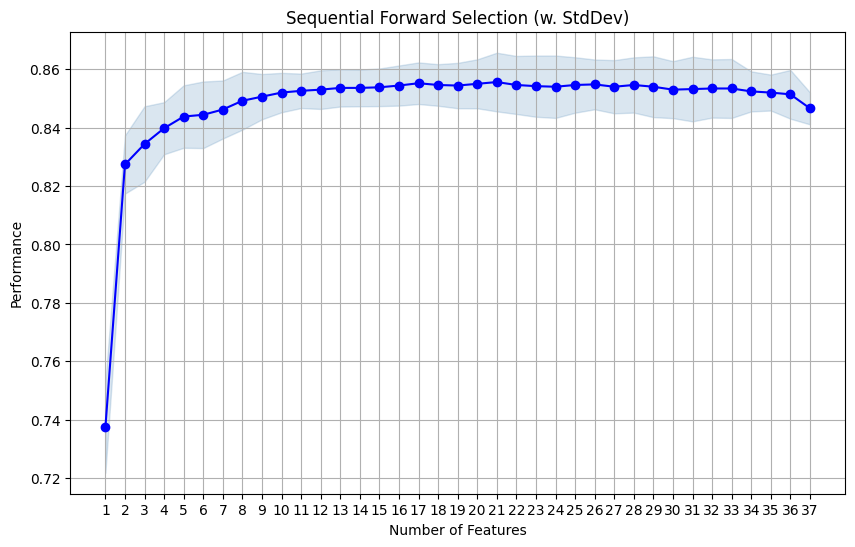

In [83]:
from mlxtend.plotting import plot_sequential_feature_selection as plot_sfs
import matplotlib.pyplot as plt

fig1 = plot_sfs(sfs_back.get_metric_dict(), kind='std_dev')

#plt.ylim([0.8, 1])
plt.title('Sequential Forward Selection (w. StdDev)')
plt.grid()
plt.show()


**Modelo forward por parsimonia**
  


In [84]:
# Sequential Forward Selection
sfs_forw_par = sfs(clf,
                   k_features='parsimonious',
                   forward=True,
                   floating=False,
                   cv=4,n_jobs=-1)

sfs_forw_par = sfs_forw_par.fit(X, y_)

print('\nSequential Forward Selection (Parsimonia):')
print(sfs_forw_par.k_feature_names_)
print('CV Score:')
print(sfs_forw_par.k_score_)



Sequential Forward Selection (Parsimonia):
('view[T.1]', 'bedrooms_cat[T.Raros]', 'floors_cat[T.2.5+]', 'lat_rec[T.[47.53, inf)]', 'sqft_living', 'sqft_above', 'yr_built', 'lat', 'long', 'aleatorio2', 'lat_sqr', 'long_log')
CV Score:
0.8555702161729384


## Selección de variables con interacciones

Vamos ahora a considerar los efectos de interacción de orden 2 entre las variables para valorar si pueden aportar capacidad predictiva al modelo.

Generaremos el dataset con las interacciones de todas las variables y posteriormente pasaremos los métodos de selección para hacer una criba de efectos interesantes.


In [85]:
# Aplicamos a fórmula de modelo completo
formR=ols_formula(data_transf,'Luxury','month','bathrooms', 'yr_built','bedrooms_cat',
                  'year', 'condition','basement', 'yr_renovated', 'prop_missings','aleatorio','aleatorio2',
                  'floors_cat','long','sqft_ratio','sqft_sum','lat')

# Generamos las matrices de diseño según la fórmula de modelo completo
y_int, X_int = patsy.dmatrices(formR, data_transf, return_type='dataframe')
X_int.columns


Index(['Intercept', 'waterfront[T.1]', 'view[T.1]', 'lat_rec[T.[47.53, inf)]',
       'sqft_living', 'sqft_above', 'bedrooms_cont', 'log_sqft_lot', 'floors',
       'month_raiz4', 'lat_sqr', 'long_log'],
      dtype='object')

Creamos las interacciones de todas las variables.



In [86]:
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures

# Create interaction terms (interaction of each regressor pair + polynomial)
#Interaction terms need to be created in both the test and train datasets
interaction = PolynomialFeatures(degree=2, include_bias=False, interaction_only=True)
interaction

#traning
#imput_inter = pd.DataFrame(interaction.fit_transform(imput_red), columns=interaction.get_feature_names_out(input_features=imput_red.columns))
X_inter = pd.DataFrame(interaction.fit_transform(X_int.drop('Intercept',axis=1)), columns=interaction.get_feature_names_out(input_features=X_int.drop('Intercept',axis=1).columns))


Eliminamos interacciones sin sentido.



In [87]:
# Eliminar columnas constantes (interacciones sin sentido)
X_inter = X_inter.loc[:, X_inter.var() != 0.0]

X_inter['Intercept'] = X.Intercept
X_inter.shape

(4999, 67)

Como son muchísimos efectos y la selección de variables es computacionalmente costosa, nos planteamos escoger como interacciones aquellas que parezcan más relevantes para explicar la variable objetivo.

Por ello, vamos a calcular el valor de vCramer de todos los efectos frente a la objetivo y filtrar aquellos con valores más elevados.


In [88]:
# Aplicar la función al input completo contra la objetivo
tablaCramer = pd.DataFrame(X_inter.apply(lambda x: cramers_v(x,varObjBin)),columns=['VCramer'])
tablaCramer.sort_values(by='VCramer', ascending=False)


,VCramer
"lat_rec[T.[47.53, inf)] sqft_living",0.633280
"lat_rec[T.[47.53, inf)] sqft_above",0.592798
"lat_rec[T.[47.53, inf)] bedrooms_cont",0.542177
sqft_living,0.528181
"lat_rec[T.[47.53, inf)] lat_sqr",0.525138
lat_sqr,0.515023
"lat_rec[T.[47.53, inf)] floors",0.514292
sqft_living log_sqft_lot,0.489715
sqft_living lat_sqr,0.484690
"lat_rec[T.[47.53, inf)] log_sqft_lot",0.478941


Selección de valores mayores que 0.4.



In [89]:
selec = tablaCramer[tablaCramer.VCramer > 0.45].index.tolist()


Genero la selección en los datos y vamos a juntar el archivo original X con este subconjunto de efectos interesantes. Ya que algunos de los elegidos ya están en X (variables originales potentes) lo mejor es eliminarlos para hacer el join, de lo contrario te pediría un sufijo para aquellas variables cuyo nombre está en ambos archivos...se doblarían mismas variables con nombres distintos y sería un jaleo.



In [90]:
# Selección de interacciones
datasel = X_inter[selec]

# Junto X con las interacciones buenas
datatot = pd.concat([X, datasel], axis=1)
datatot.shape

# Elimino columnas duplicadas (en datasel podría haber efectos ppales!!)
datatot = datatot.T.drop_duplicates().T
datatot.head()



,Intercept,year[T.2015],waterfront[T.1],view[T.1],condition[T.A],condition[T.B],condition[T.CD],basement[T.1],yr_renovated[T.1],bedrooms_cat[T.3],bedrooms_cat[T.4],bedrooms_cat[T.5],bedrooms_cat[T.6-10],bedrooms_cat[T.<2],bedrooms_cat[T.Raros],floors_cat[T.1.5],floors_cat[T.2.0],floors_cat[T.2.5+],"lat_rec[T.[47.53, inf)]",month,bathrooms,sqft_living,sqft_above,yr_built,lat,long,bedrooms_cont,log_sqft_lot,prop_missings,floors,aleatorio,aleatorio2,month_raiz4,lat_sqr,long_log,sqft_ratio,sqft_sum,"lat_rec[T.[47.53, inf)] sqft_living","lat_rec[T.[47.53, inf)] sqft_above","lat_rec[T.[47.53, inf)] bedrooms_cont","lat_rec[T.[47.53, inf)] log_sqft_lot","lat_rec[T.[47.53, inf)] floors","lat_rec[T.[47.53, inf)] lat_sqr",sqft_living bedrooms_cont,sqft_living log_sqft_lot,sqft_living month_raiz4,sqft_living lat_sqr,log_sqft_lot lat_sqr
0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,7.0,2.5,2070.0,1540.0,1980.0,47.5936,-122.013,3.0,9.301094,5.882353,1.0,0.471773,0.625597,1.177619,10.029352,1.253926,1.344156,3610.0,2070.0,1540.0,3.0,9.301094,1.0,10.029352,6210.0,19253.265397,2437.670497,20760.757768,93.283946
1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,6.0,1.5,1640.0,1540.0,1916.0,47.6624,-122.325,2.0,9.053580,5.882353,1.5,0.967475,0.883987,1.125150,13.429967,0.248454,1.064935,3180.0,1640.0,1540.0,2.0,9.053580,1.5,13.429967,3280.0,14847.871597,1845.246207,22025.145417,121.589281
2,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.0,3.5,3720.0,3720.0,2007.0,47.3216,-121.940,4.0,10.139560,5.882353,1.0,0.078995,0.978015,1.303244,1.437506,1.392269,1.000000,7440.0,0.0,0.0,0.0,0.000000,0.0,0.000000,14880.0,37719.161573,4848.066056,5347.523971,14.575682
3,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,12.0,3.5,2260.0,1880.0,2003.0,47.6422,-122.361,3.0,8.218188,5.882353,2.0,0.804842,0.558699,1.370290,12.380140,0.025330,1.202128,4140.0,2260.0,1880.0,3.0,8.218188,2.0,12.380140,6780.0,18573.104697,3096.855114,27979.116707,101.742318
4,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,10.0,2.0,2050.0,1170.0,1960.0,47.7447,-122.328,3.0,8.650238,5.882353,1.0,0.215817,0.758183,1.303244,18.148817,0.231648,1.752137,3220.0,2050.0,1170.0,3.0,8.650238,1.0,18.148817,6150.0,17732.987240,2671.649305,37205.075297,156.991583


Ya tenemos el archivo con variables originales, transformaciones de continuas y las interacciones que parecen más relevantes.

Aplicamos selección de variables por parsimonia y mejor para valorar.


In [91]:
# Sequential Forward Selection
sfs_forw_int_par = sfs(clf,
                       k_features='parsimonious',
                       forward=True,
                       floating=False,
                       cv=4,n_jobs=-1)

sfs_forw_int_par = sfs_forw_int_par.fit(datatot, y_)

print('\nSequential Forward Selection transformaciones+interacciones (parsimonia):')
print(sfs_forw_int_par.k_feature_names_)
print('CV Score:')
print(sfs_forw_int_par.k_score_)



Sequential Forward Selection transformaciones+interacciones (parsimonia):
None
CV Score:
None



STOPPING EARLY DUE TO KEYBOARD INTERRUPT...

Visual del proceso



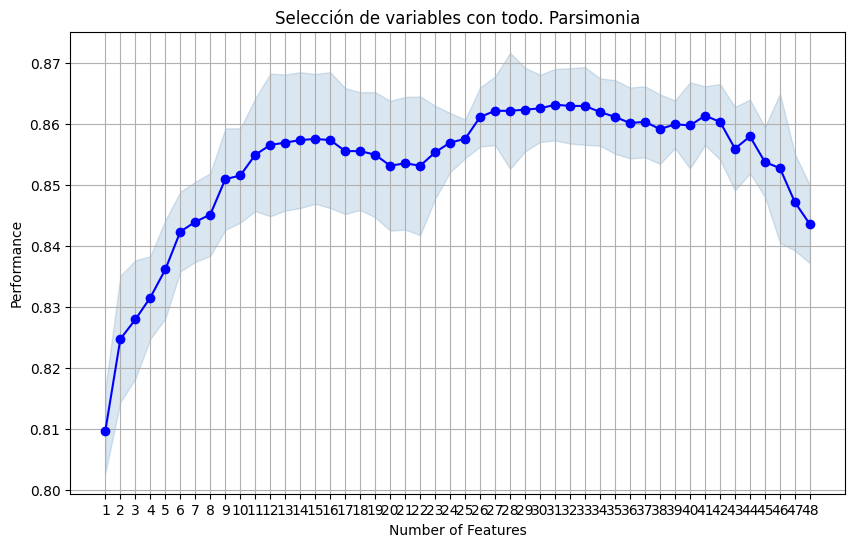

In [ ]:
fig1 = plot_sfs(sfs_forw_int_par.get_metric_dict(), kind='std_dev')

#plt.ylim([0.8, 1])
plt.title('Selección de variables con todo. Parsimonia')
plt.grid()
plt.show()


Selección de las 10 variables mejores.



In [ ]:
# Sequential Forward Selection
sfs_back_int_10 = sfs(clf,
                      k_features=10,
                      forward=False,
                      floating=False,
                      cv=4,n_jobs=-1)

sfs_back_int_10 = sfs_back_int_10.fit(datatot, y_)

print('\nSequential Forward Selection tranformaciones+interacciones 10 variables:')
print(sfs_back_int_10.k_feature_names_)
print('CV Score:')
print(sfs_back_int_10.k_score_)



Sequential Forward Selection tranformaciones+interacciones 10 variables:
('view[T.1]', 'yr_built', 'long', 'lat_sqr', 'long_log', 'lat_rec[T.[47.53, inf)] sqft_above', 'lat_rec[T.[47.53, inf)] log_sqft_lot', 'lat_rec[T.[47.53, inf)] lat_sqr', 'sqft_living log_sqft_lot', 'log_sqft_lot lat_sqr')
CV Score:
0.8549682946357087


## Selección de variables por LASSO

Exploramos la selección de variables por modelo Lasso con y sin interacciones. En el caso de regresión logística, recurrimos a la misma función LogisticRegression con la penalización l1 que es la propia del modelo Lasso. Existen 2 solvers bajo esta penalización 'saga' y 'liblinear'. Además tenemos la posibilidad de aplicar el parámetro de regularización (por defecto 1) obteniendo una penalización más agresiva en caso de consignar valores más bajos.


In [ ]:
from sklearn import linear_model

# Definición de modelo
lasso = LogisticRegression(solver='liblinear', max_iter=1000,penalty='l1',C=0.1)


lasso.fit(X, y_)

print(lasso.coef_)


[[ 0.00000000e+00  2.37641912e-01  0.00000000e+00  1.68391109e+00
   1.16076208e-01 -6.39358303e-02  0.00000000e+00  2.54413609e-01
   0.00000000e+00 -4.01155524e-02  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00  1.07688866e-01
  -1.94222811e-01  0.00000000e+00  3.66473865e+00 -1.73397929e-02
   1.85140176e-01  1.42533860e-03  6.16154964e-04 -1.42442340e-02
   2.37768065e-01 -7.44032655e-02 -2.83892276e-01  0.00000000e+00
   9.69709416e-03  3.25688083e-01  0.00000000e+00 -7.53751087e-04
   0.00000000e+00 -6.44293024e-02 -2.25383305e-01  0.00000000e+00
   4.22014585e-04]]


In [ ]:
selec_feats = X[X.columns[(lasso.coef_ != 0).ravel().tolist()]]
selec_feats.columns.tolist()


['year[T.2015]',
 'view[T.1]',
 'condition[T.A]',
 'condition[T.B]',
 'basement[T.1]',
 'bedrooms_cat[T.3]',
 'floors_cat[T.1.5]',
 'floors_cat[T.2.0]',
 'lat_rec[T.[47.53, inf)]',
 'month',
 'bathrooms',
 'sqft_living',
 'sqft_above',
 'yr_built',
 'lat',
 'long',
 'bedrooms_cont',
 'prop_missings',
 'floors',
 'aleatorio2',
 'lat_sqr',
 'long_log',
 'sqft_sum']

Lasso con todas las interacciones de X_inter. Vamos a poner muy bajo el parámetro C que controla la intensidad de la regularización aplicada por la optimización con restricciones del modelo con penalización 'l1'. De esta forma tendremos una selección de menor número de efectos de interacción por si luego queremos utilizarlos.


In [ ]:

# Definición de modelo
lasso2 = LogisticRegression(solver='liblinear', max_iter=1000,penalty='l1',C=0.05)


lasso2.fit(X_inter, y_)

print(lasso2.coef_)

[[ 0.00000000e+00  0.00000000e+00  0.00000000e+00 -9.80635983e-04
  -1.58127798e-03  0.00000000e+00 -5.30814484e-01  0.00000000e+00
   0.00000000e+00  3.48642141e-01  0.00000000e+00  0.00000000e+00
   0.00000000e+00  4.30293879e-03 -3.53539029e-03  0.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  7.70903830e-04 -1.08767940e-04
   0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   3.58993367e-02  0.00000000e+00  1.16741064e-03  3.89517653e-05
   0.00000000e+00  4.46692600e-01  0.00000000e+00  0.00000000e+00
  -4.29868173e-01  0.00000000e+00 -2.55166764e-07 -5.82670847e-05
   2.43206260e-04  5.57488506e-04  8.96431292e-05 -3.83850089e-05
   3.70779398e-04 -4.22245581e-05  3.38723578e-04  2.62739652e-04
  -1.76399397e-04 -1.64554088e-05  3.74860203e-05 -2.99359424e-02
   0.00000000e+00  0.00000000e+00  1.72710006e-02  0.00000000e+00
  -2.83205880e-01 -1.71581377e-02 -9.82993840e-03 -8.56344405e-02
   0.00000

In [ ]:
selec_feats_int = X_inter[X_inter.columns[(lasso2.coef_ != 0).ravel().tolist()]]
selec_feats_int.columns.tolist()


['sqft_living',
 'sqft_above',
 'log_sqft_lot',
 'lat_sqr',
 'waterfront[T.1] sqft_living',
 'waterfront[T.1] sqft_above',
 'view[T.1] sqft_living',
 'view[T.1] sqft_above',
 'view[T.1] lat_sqr',
 'lat_rec[T.[47.53, inf)] sqft_living',
 'lat_rec[T.[47.53, inf)] sqft_above',
 'lat_rec[T.[47.53, inf)] log_sqft_lot',
 'lat_rec[T.[47.53, inf)] lat_sqr',
 'sqft_living sqft_above',
 'sqft_living bedrooms_cont',
 'sqft_living log_sqft_lot',
 'sqft_living floors',
 'sqft_living month_raiz4',
 'sqft_living lat_sqr',
 'sqft_living long_log',
 'sqft_above bedrooms_cont',
 'sqft_above log_sqft_lot',
 'sqft_above floors',
 'sqft_above month_raiz4',
 'sqft_above lat_sqr',
 'sqft_above long_log',
 'bedrooms_cont log_sqft_lot',
 'bedrooms_cont lat_sqr',
 'log_sqft_lot floors',
 'log_sqft_lot month_raiz4',
 'log_sqft_lot lat_sqr',
 'log_sqft_lot long_log',
 'floors lat_sqr',
 'lat_sqr long_log']

## Comparación por validación cruzada

Comparamos el rendimiento de los modelos bajo el esquema de validación cruzada repetida creando una función similar a la que ya teníamos pero que, en esta ocasión trabaja sobre objetos de salida de los métodos de selección de variables de tal forma que en base a estos se seleccione el input adecuado y se ajuste el modelo lineal con las variables seleccionadas.


In [ ]:
#list_sfs = [selec_feats,selec_feats_int]
list_sfs = [sfs_back,sfs_forw_par,sfs_forw_int_par,sfs_back_int_10,selec_feats,selec_feats_int]

#data = imput_dummy.join(imput_inter,lsuffix="_left")

# Aplicamos a toda la lista la función creada (devuelve un dataframe pero está transpuesto)
list_res = pd.DataFrame(map(lambda x: cross_val_selectVar(x,datatot,y,log=True, seed=2022),list_sfs))

# Trasnponer dataframe y pasar de wide a long (creando un factor variable con el nombre de cada fórmula de la lista[0,1,2,3])

results_lasso = list_res.T.set_axis(['sfs_back','sfs_forw_par','sfs_forw_int_par',
                                     'sfs_back_int_10','selec_feats','selec_feats_int'],axis=1).melt()
results_lasso.columns = ['Modelo','AUC']
results_lasso.head()


Métrica roc_auc: 0.929 (0.008)
Métrica roc_auc: 0.927 (0.008)
Métrica roc_auc: 0.937 (0.007)
Métrica roc_auc: 0.935 (0.007)
Métrica roc_auc: 0.928 (0.008)
Métrica roc_auc: 0.918 (0.008)


,Modelo,AUC
0,sfs_back,0.922788
1,sfs_back,0.933184
2,sfs_back,0.935388
3,sfs_back,0.921183
4,sfs_back,0.933569


In [ ]:
# Extraemos la matriz X de predictores para el modelo sfs_back_int_10
#list_sfs

In [ ]:
 X = pd.DataFrame(sfs_back_int_10.transform(datatot))
 X.columns = sfs_back_int_10.k_feature_names_
X=pd.concat([datatot.Intercept,X],axis=1)
X.head()

,Intercept,view[T.1],yr_built,long,lat_sqr,long_log,"lat_rec[T.[47.53, inf)] sqft_above","lat_rec[T.[47.53, inf)] log_sqft_lot","lat_rec[T.[47.53, inf)] lat_sqr",sqft_living log_sqft_lot,log_sqft_lot lat_sqr
0,1.0,0.0,1980.0,-122.013,10.029352,1.253926,1540.0,9.301094,10.029352,19253.265397,93.283946
1,1.0,0.0,1916.0,-122.325,13.429967,0.248454,1540.0,9.053580,13.429967,14847.871597,121.589281
2,1.0,1.0,2007.0,-121.940,1.437506,1.392269,0.0,0.000000,0.000000,37719.161573,14.575682
3,1.0,0.0,2003.0,-122.361,12.380140,0.025330,1880.0,8.218188,12.380140,18573.104697,101.742318
4,1.0,0.0,1960.0,-122.328,18.148817,0.231648,1170.0,8.650238,18.148817,17732.987240,156.991583


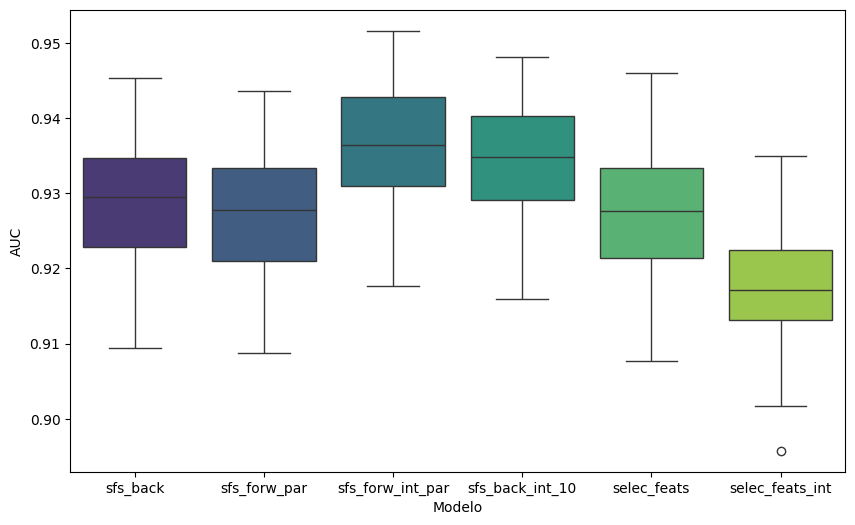

In [ ]:
plt.rcParams["figure.figsize"] = (10,6)
plt.clf()
# Boxplot paralelo para comparar
sns.boxplot(x='Modelo',y='AUC',data=results_lasso,palette='viridis')
plt.show()


## Posibilidad de selección de variables por Random Forest

Siempre tenemos muchas posibilidades de selección de variables o al menos cálculo de la importancia de los efectos en modelo.

Ver https://machinelearningmastery.com/calculate-feature-importance-with-python/

En este caso, como los modelos con interacciones son bastante bueno, intentaremos rescatar efectos interesantes para añadir al modelo manual y acercarnos a capacidades predictivas superiores.

Vamos a reciclar una función de la anterior fuente y nos la tuneamos para que funcione como queremos.



In [ ]:
# evaluation of a model using 5 features chosen with random forest importance
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# feature selection
def select_features(X,y,n_feat=5):
 #formula=ols_formula(data,target)
 #y, X = patsy.dmatrices(formula, data, return_type='dataframe')
 #y = y.iloc[:,0].ravel()
 # Definir modelo
 fs = SelectFromModel(RandomForestClassifier(n_estimators=1000), max_features=n_feat)
 # Ajuste
 fs.fit(X, y)
 # Selección efectiva de colunmas
 X_fs = fs.transform(X)
 X_fs = pd.DataFrame(X_fs)
 X_fs.columns=fs.get_feature_names_out()

 return X_fs

X_fs=select_features(X,y,10)

X_fs.head()


,lat_sqr,"lat_rec[T.[47.53, inf)] sqft_above",sqft_living log_sqft_lot,log_sqft_lot lat_sqr
0,10.029352,1540.0,19253.265397,93.283946
1,13.429967,1540.0,14847.871597,121.589281
2,1.437506,0.0,37719.161573,14.575682
3,12.380140,1880.0,18573.104697,101.742318
4,18.148817,1170.0,17732.987240,156.991583


**Ajuste y evaluación del modelo con selección de variables por RF.**


In [ ]:
from statsmodels.discrete.discrete_model import Logit

# Ajustar modelo con selección de varianles RF
modeloRF = Logit(y, X_fs).fit()
print(modeloRF.summary())

# Podríamos generar el data total de este modelo con la objetivo y utillizar formula
data_fs = pd.concat([X_fs,y],axis=1)
data_fs.columns = data_fs.columns.str.replace(' ', '')
data_fs.columns = data_fs.columns.str.replace('[T.[47.53,inf)]', '')
print(data_fs.columns)
# Generamos la formula
form_fs=ols_formula(data_fs,'Luxury')
print(form_fs)
# Evaluación en tr/tst
tr_tst_eval_log(form_fs,data =data_fs)


Optimization terminated successfully.
         Current function value: 0.497985
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                 Luxury   No. Observations:                 4999
Model:                          Logit   Df Residuals:                     4995
Method:                           MLE   Df Model:                            3
Date:                Mon, 02 Jun 2025   Pseudo R-squ.:                  0.2689
Time:                        17:20:49   Log-Likelihood:                -2489.4
converged:                       True   LL-Null:                       -3405.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                         coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
lat_sqr                               -0.3478      0.036    

**Ajuste y evaluación del modelo con selección de variables por SFS con interacciones y 10 variables.**

In [ ]:

# Ajustar modelo SFS 10
modeloSFS = Logit(y, X).fit()
print(modeloSFS.summary())


Optimization terminated successfully.
         Current function value: 0.323194
         Iterations 9
                           Logit Regression Results                           
Dep. Variable:                 Luxury   No. Observations:                 4999
Model:                          Logit   Df Residuals:                     4988
Method:                           MLE   Df Model:                           10
Date:                Mon, 02 Jun 2025   Pseudo R-squ.:                  0.5255
Time:                        17:20:49   Log-Likelihood:                -1615.6
converged:                       True   LL-Null:                       -3405.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                           coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------
Intercept                               55.2931     98.0

In [ ]:
def tr_tst_eval_log_Xy(X,y):
  # Generamos las matrices de diseño según la fórmula de modelo completo
  #y, X = patsy.dmatrices(formula, data, return_type='dataframe')

  # Creamos 4 objetos: predictores para tr y tst y variable objetivo para tr y tst.
  X_tr, X_tst, y_tr, y_tst = train_test_split(X, y, test_size=0.2, random_state=1234)

  # Definición de modelo
  modelo = LogisticRegression(solver='lbfgs', max_iter=2000,penalty=None)

  # Arreglar y para que le guste a sklearn...numeric
  y_tr_ = y_tr.iloc[:,0].ravel()

  # Ajuste de modelo
  modelLog = modelo.fit(X_tr,y_tr_)

  # Accuracy del modelo en training
  acc = modelLog.score(X_tr,y_tr_)
  print('Accuracy en training: ',acc, '\n')

  # Predicciones en test
  y_pred = modelLog.predict(X_tst)
  print(modelLog.predict_proba(X_tst)[:5])
  print(modelLog.predict(X_tst)[:5])
  # Matriz de confusion de clasificación
  print('Matriz de confusión y métricas derivadas: \n',metrics.confusion_matrix(y_tst,y_pred))

  # Reporte de clasificación
  print(metrics.classification_report(y_tst,y_pred))

  # Extraemos el Area bajo la curva ROC
  print('Area bajo la curva ROC training: \n', metrics.roc_auc_score(y_tr, modelLog.predict_proba(X_tr)[:, 1]))
  print('Area bajo la curva ROC test: \n', metrics.roc_auc_score(y_tst, modelLog.predict_proba(X_tst)[:, 1]))



**Aquí no me dejaba utilizar fórmula data así que me he copiado y modificado la función tr_tst y la he tuneado**

In [ ]:
data_sfs = pd.concat([data_transf,X.Intercept],axis=1)
print(data_sfs.columns)
# Generamos la formula
form_sfs10=ols_formula(data_sfs,'Luxury')
print(form_sfs10)

#form1='Luxury ~ Intercept + year + view + condition'# + basement + floors_cat + sqft_living + lat_sqr + long_log + lat_rec:sqft_above + lat_rec:log_sqft_lot + lat_rec:lat_sqr + log_sqft_lot:lat_sqr'

# Evaluación en tr/tst
tr_tst_eval_log_Xy(X,y)

Index(['month', 'bathrooms', 'sqft_living', 'sqft_above', 'yr_built', 'lat',
       'long', 'bedrooms_cont', 'log_sqft_lot', 'prop_missings', 'year',
       'floors', 'waterfront', 'view', 'condition', 'basement', 'yr_renovated',
       'bedrooms_cat', 'aleatorio', 'aleatorio2', 'floors_cat', 'month_raiz4',
       'lat_sqr', 'long_log', 'Luxury', 'sqft_ratio', 'sqft_sum', 'lat_rec',
       'Intercept'],
      dtype='object')
Luxury ~ month + bathrooms + sqft_living + sqft_above + yr_built + lat + long + bedrooms_cont + log_sqft_lot + prop_missings + year + floors + waterfront + view + condition + basement + yr_renovated + bedrooms_cat + aleatorio + aleatorio2 + floors_cat + month_raiz4 + lat_sqr + long_log + sqft_ratio + sqft_sum + lat_rec + Intercept
Accuracy en training:  0.8574643660915229 

[[0.95934857 0.04065143]
 [0.69187078 0.30812922]
 [0.48857966 0.51142034]
 [0.03999211 0.96000789]
 [0.91371401 0.08628599]]
[0. 0. 1. 1. 0.]
Matriz de confusión y métricas derivadas: 
 [[518  

Se obtiene mejora en las métricas pero el modelo es complejo, con mucha interacción de lat y efectos tranformados de la misma variable, posible colinealidad por sqft_above... No parece que merezca la pena..


# Interpretación y Evaluación del modelo ganador

Con el modelo final, ajustamos en datos completos para obtener los estimadores con mayor robustez posible de cara a la interpretación.


In [ ]:
form15 = 'Luxury ~ sqft_living+lat_rec+floors+bedrooms_cont+view+bathrooms+year+yr_built'

# Ajustar modelo 1
modeloF = logit(form15,data=data_transf).fit()
print(modeloF.summary())

tr_tst_eval_log(form15,data =data_transf)


Optimization terminated successfully.
         Current function value: 0.342460
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:                 Luxury   No. Observations:                 4999
Model:                          Logit   Df Residuals:                     4990
Method:                           MLE   Df Model:                            8
Date:                Mon, 02 Jun 2025   Pseudo R-squ.:                  0.4972
Time:                        17:20:49   Log-Likelihood:                -1712.0
converged:                       True   LL-Null:                       -3405.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                  28.5667      3.637      7.855      0.000      21.439   

## Interpretación de los parámetros del modelo final



In [ ]:
modeloF.params.info()#round(2)

<class 'pandas.core.series.Series'>
Index: 9 entries, Intercept to yr_built
Series name: None
Non-Null Count  Dtype  
--------------  -----  
9 non-null      float64
dtypes: float64(1)
memory usage: 144.0+ bytes


In [ ]:

pd.options.display.float_format = '{:.4f}'.format

ORs = np.exp(modeloF.params)

print(ORs[1:len(ORs)])

lat_rec[T.[47.53, inf)]   24.8497
view[T.1]                  7.8304
year[T.2015]               1.5103
sqft_living                1.0027
floors                     1.9804
bedrooms_cont              0.7073
bathrooms                  1.2342
yr_built                   0.9813
dtype: float64


En base a los ORs del modelo podemos concluir que:

1. Es 24,8 veces más probable encontrar vivienda de lujo en latitudes mayores que 47.53 que en la referencia.
2. Es 7,8 veces más probable ser vivienda de lujo si se tienen vistas.
3. Es 1,5 veces más probable (la probabilidad aumenta un 50%) encontrar vivienda de lujo en 2015 que en 2014 (esta seguramente deberíamos pasarla a continua para poner el modelo en producción).
4. El aumento unitario de la superficie del salón provoca un aumento de la probabilidad de lujo de la vivienda de un 0,27%. La probabilidad de vivienda de lujo es 1.0027 veces mayor con cada aumento unitario de la superficie del salón.
5. Es 1,98 veces más probable encontrar vivienda de lujo por cada aumento unitario del número de plantas de la viveienda.
6. El aumento unitario del número de habitaciones disminuye la probabilidad de lujo en un 29,3%.
7. El aumento unitario del año de contrucción produce una disminución de la probabilidad de lujo del 2%.
8. El aumento unitario del número de baños produce un aumento del 23% en el Odds de vivienda de lujo.

Todo esto, por supuesto, ceteris paribus.


## Búsqueda del punto de corte óptimo de la probabilidad estimada


In [ ]:
# Creamos 4 objetos: predictores para tr y tst y variable objetivo para tr y tst.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1234)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((3999, 11), (1000, 11), (3999, 1), (1000, 1))

Optimization terminated successfully.
         Current function value: 0.322655
         Iterations 9
<class 'pandas.core.series.Series'>
Index: 1000 entries, 2705 to 4415
Series name: None
Non-Null Count  Dtype  
--------------  -----  
1000 non-null   float64
dtypes: float64(1)
memory usage: 15.6 KB
None
<class 'pandas.core.frame.DataFrame'>
Index: 1000 entries, 2705 to 4415
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Luxury  1000 non-null   float64
dtypes: float64(1)
memory usage: 15.6 KB
None


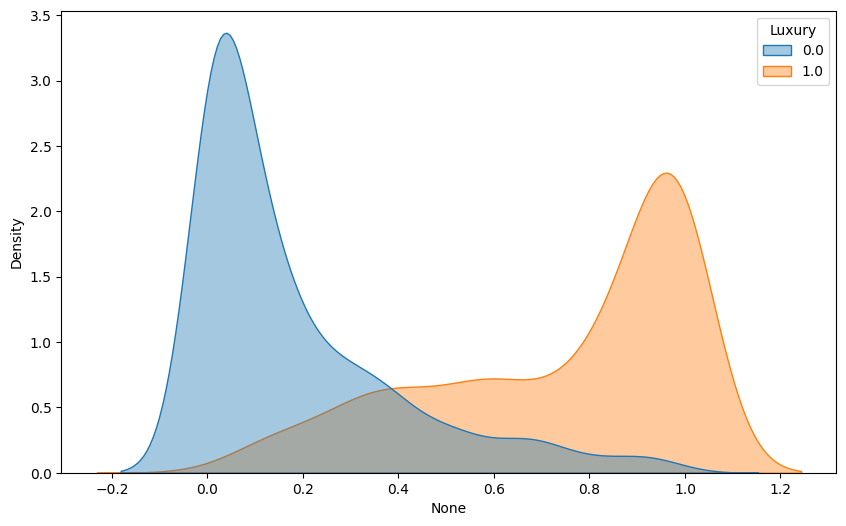

In [ ]:
## BUscamos el mejor punto de corte
from statsmodels.discrete.discrete_model import Logit
# Ajustar modelo 1
modeloF = Logit(y_train, X_train).fit()
#modeloF.summary()
y_pred = modeloF.predict(X_test)
print(y_pred.info())
print(y_test.info())
#sns.histplot(x=y_pred, hue=y_test)
#px.histogram(x=y_pred, color=y_test).show()
#gráfico de las probabilidades obtenidas
plt.clf()
sns.kdeplot(x=y_pred, hue=y_test.Luxury, fill=True, common_norm=False, alpha=0.4)
plt.show()
#hist_targetbinaria(predict(modelo4, newdata=data_test,type="response"),data_test$varObjBin,"probabilidad")


In [ ]:
roc_grafico(y_test,y_pred)



In [ ]:

corte = cutoff_youden(y_test,y_pred)
corte


0.3883635701867873

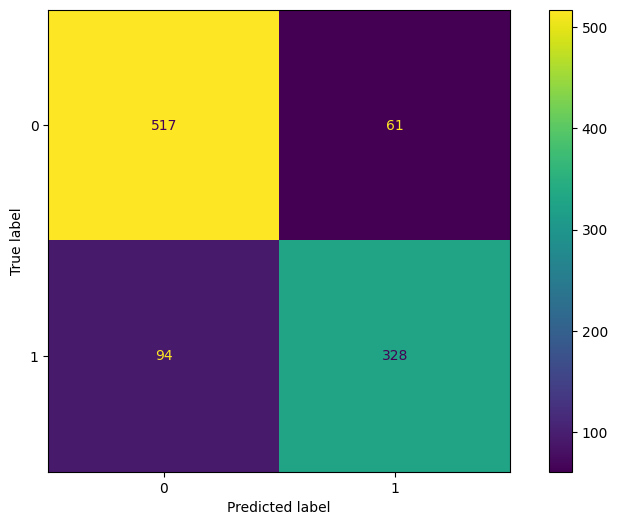

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, round(y_pred))

cm_display = ConfusionMatrixDisplay(cm).plot()
cm_display
plt.show()


In [ ]:
# Reporte de clasificación
print(metrics.classification_report(y_test,round(y_pred)))


              precision    recall  f1-score   support

         0.0       0.85      0.89      0.87       578
         1.0       0.84      0.78      0.81       422

    accuracy                           0.84      1000
   macro avg       0.84      0.84      0.84      1000
weighted avg       0.84      0.84      0.84      1000



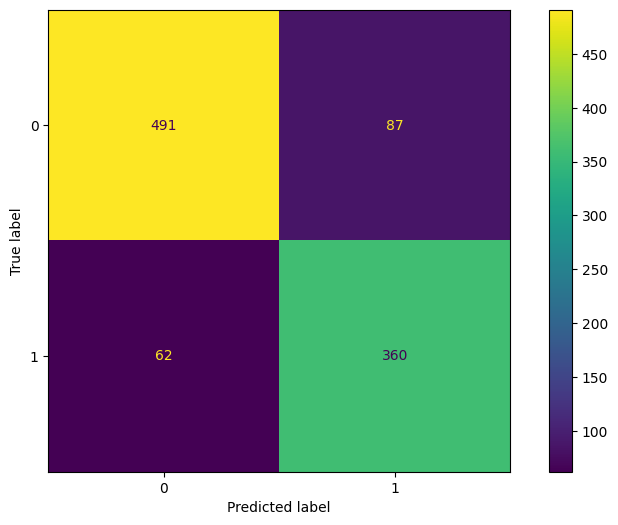

              precision    recall  f1-score   support

         0.0       0.89      0.85      0.87       578
         1.0       0.81      0.85      0.83       422

    accuracy                           0.85      1000
   macro avg       0.85      0.85      0.85      1000
weighted avg       0.85      0.85      0.85      1000



In [ ]:
y_clas =  y_pred.map(lambda x: 1 if x > corte else 0)

cm = confusion_matrix(y_test, y_clas)

cm_display = ConfusionMatrixDisplay(cm).plot()
cm_display
plt.show(cm_display)

# Reporte de clasificación
print(metrics.classification_report(y_test,y_clas))


Con el punto de corte en el entorno de Youden se obtiene equilibro entre sensibilidad y especificidad y buen accuracy!

